<a href="https://colab.research.google.com/github/thegurdian/ML/blob/main/age%20based%20diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Colab cell 1 — Install libraries and import packages

In [3]:
!pip -q install ucimlrepo xgboost shap

import os
import warnings
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from scipy.special import expit, logit

from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    log_loss
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

from IPython.display import display

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")

os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/tables", exist_ok=True)
os.makedirs("results/models", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


# Colab cell 2 — Download PIMA dataset

In [4]:
# Download Pima Indians Diabetes Dataset from a reliable public CSV URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

# Define the original features and target based on standard PIMA dataset format
columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

# Read the CSV file
df_all = pd.read_csv(url, names=columns)

# Split into features (X_raw) and targets (y_raw) to match your pipeline's format
X_raw = df_all.drop(columns=["Outcome"]).copy()
y_raw = df_all[["Outcome"]].copy()

print("Original feature shape:", X_raw.shape)
print("Original target shape:", y_raw.shape)

display(X_raw.head())
display(y_raw.head())

Original feature shape: (768, 8)
Original target shape: (768, 1)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


,Outcome
0,1
1,0
2,1
3,0
4,1


# Colab cell 3 — Standardize column names

In [5]:
df = X_raw.copy()

df.columns = [
    str(col).strip().lower().replace(" ", "_")
    for col in df.columns
]

print("Original columns:")
print(df.columns.tolist())

# Map original UCI names to standard PIMA names
column_mapping = {
    "preg": "Pregnancies",
    "pregnancies": "Pregnancies",

    "plas": "Glucose",
    "glucose": "Glucose",

    "pres": "BloodPressure",
    "diastolic": "BloodPressure",
    "bloodpressure": "BloodPressure",

    "skin": "SkinThickness",
    "triceps": "SkinThickness",
    "skinthickness": "SkinThickness",

    "insu": "Insulin",
    "insulin": "Insulin",

    "mass": "BMI",
    "bmi": "BMI",

    "pedi": "DiabetesPedigreeFunction",
    "dpf": "DiabetesPedigreeFunction",
    "diabetespedigreefunction": "DiabetesPedigreeFunction",

    "age": "Age"
}

df.rename(columns=column_mapping, inplace=True)

# Standardize target
y_raw.columns = [
    str(col).strip().lower()
    for col in y_raw.columns
]

y = y_raw.iloc[:, 0]

if y.dtype == "object":
    y = (
        y.astype(str)
        .str.lower()
        .str.strip()
        .map({
            "tested_positive": 1,
            "tested_negative": 0,
            "positive": 1,
            "negative": 0,
            "yes": 1,
            "no": 0
        })
    )

y = pd.to_numeric(y, errors="coerce")

data = df.copy()
data["Outcome"] = y.values

# Remove rows with missing target
data = data.dropna(subset=["Outcome"])

data["Outcome"] = data["Outcome"].astype(int)

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

missing_columns = [
    col for col in FEATURES
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

data = data[FEATURES + ["Outcome"]].copy()

print("Final dataset shape:", data.shape)
print("\nClass distribution:")
print(data["Outcome"].value_counts())

display(data.head())

Original columns:
['pregnancies', 'glucose', 'bloodpressure', 'skinthickness', 'insulin', 'bmi', 'diabetespedigreefunction', 'age']
Final dataset shape: (768, 9)

Class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Colab cell 4 — Dataset quality audit

In [6]:
print("=" * 60)
print("DATASET AUDIT")
print("=" * 60)

print("Dataset shape:", data.shape)

print("\nData types:")
print(data.dtypes)

print("\nMissing values:")
display(data.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate rows:", data.duplicated().sum())

print("\nStatistical summary:")
display(data.describe().T)

print("\nClass distribution:")
display(
    data["Outcome"]
    .value_counts()
    .rename(index={0: "Non-Diabetic", 1: "Diabetic"})
    .to_frame("Count")
)

# Investigate zero values
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_report = pd.DataFrame({
    "Zero_Count": (data[zero_columns] == 0).sum(),
    "Zero_Percentage": (
        (data[zero_columns] == 0).mean() * 100
    )
})

print("\nZero-value investigation:")
display(zero_report)

zero_report.to_csv(
    "results/tables/zero_value_report.csv"
)

DATASET AUDIT
Dataset shape: (768, 9)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values:


,Missing Count
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Duplicate rows: 0

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Class distribution:


,Count
Outcome,
Non-Diabetic,500
Diabetic,268



Zero-value investigation:


,Zero_Count,Zero_Percentage
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292


Correct invalid-zero treatment

In [7]:
data_clean = data.copy()

for col in zero_columns:
    data_clean.loc[
        data_clean[col] == 0,
        col
    ] = np.nan

print("Missing values after zero treatment:")
display(data_clean.isnull().sum())

print("Valid zero pregnancies:",
      (data_clean["Pregnancies"] == 0).sum())

Missing values after zero treatment:


,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Valid zero pregnancies: 111


Colab cell 5 — Age grouping

In [8]:
AGE_BINS = [20, 30, 40, 50, 100]

AGE_LABELS = [
    "21-30",
    "31-40",
    "41-50",
    "51+"
]

data_clean["Age_Group"] = pd.cut(
    data_clean["Age"],
    bins=AGE_BINS,
    labels=AGE_LABELS,
    right=True,
    include_lowest=True
)

print("Age distribution:")
display(
    data_clean["Age_Group"]
    .value_counts()
    .sort_index()
)

age_summary = (
    data_clean
    .groupby("Age_Group", observed=False)
    .agg(
        Total=("Outcome", "count"),
        Diabetic=("Outcome", "sum"),
        Mean_Age=("Age", "mean")
    )
)

age_summary["Non_Diabetic"] = (
    age_summary["Total"] -
    age_summary["Diabetic"]
)

age_summary["Diabetes_Prevalence"] = (
    age_summary["Diabetic"] /
    age_summary["Total"] * 100
)

display(age_summary)

age_summary.to_csv(
    "results/tables/age_summary.csv"
)

Age distribution:


,count
Age_Group,
21-30,417
31-40,157
41-50,113
51+,81


,Total,Diabetic,Mean_Age,Non_Diabetic,Diabetes_Prevalence
Age_Group,,,,,
21-30,417,90,24.599520,327,21.582734
31-40,157,76,35.146497,81,48.407643
41-50,113,64,44.327434,49,56.637168
51+,81,38,58.567901,43,46.913580


Colab cell 6 — Exploratory data visualization

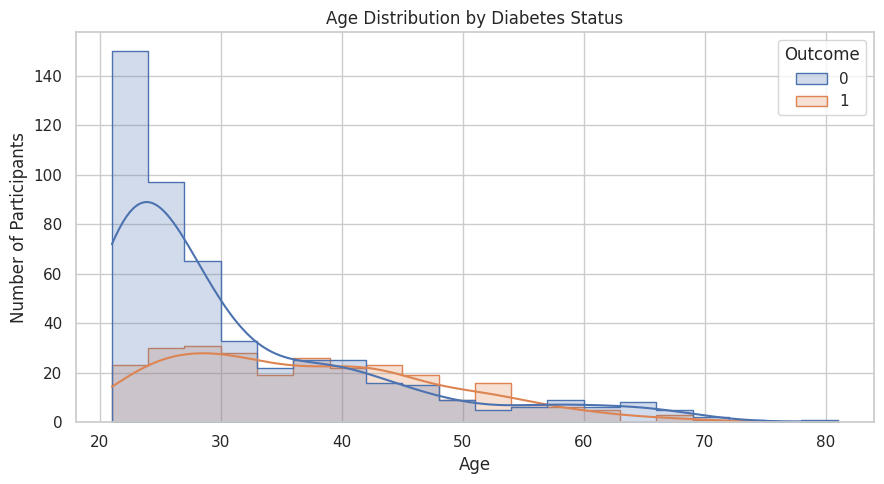

In [9]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=data_clean,
    x="Age",
    hue="Outcome",
    bins=20,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Diabetes Status")
plt.xlabel("Age")
plt.ylabel("Number of Participants")

plt.tight_layout()
plt.savefig(
    "results/figures/age_distribution.png",
    dpi=300
)
plt.show()

2. Diabetes prevalence by age group

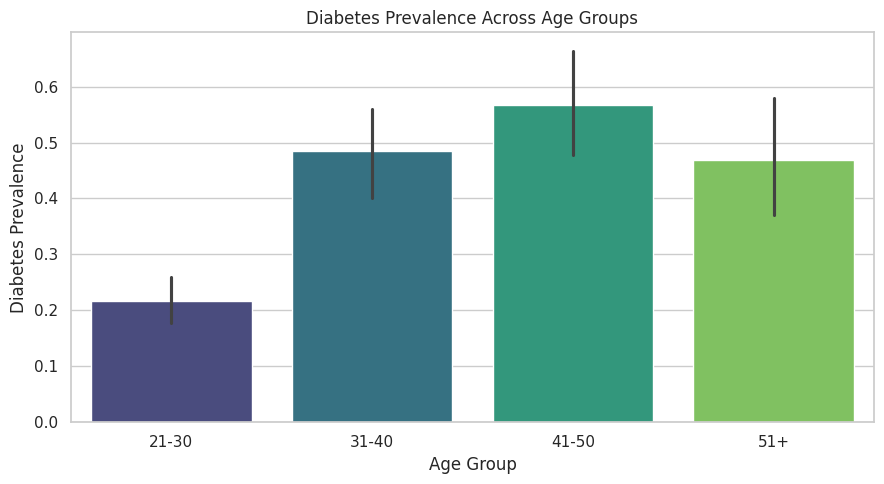

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=data_clean,
    x="Age_Group",
    y="Outcome",
    hue="Age_Group",
    estimator=np.mean,
    errorbar=("ci", 95),
    palette="viridis",
    legend=False
)

plt.title("Diabetes Prevalence Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Diabetes Prevalence")

plt.tight_layout()
plt.savefig(
    "results/figures/age_prevalence.png",
    dpi=300
)
plt.show()

3. Age group sample distribution

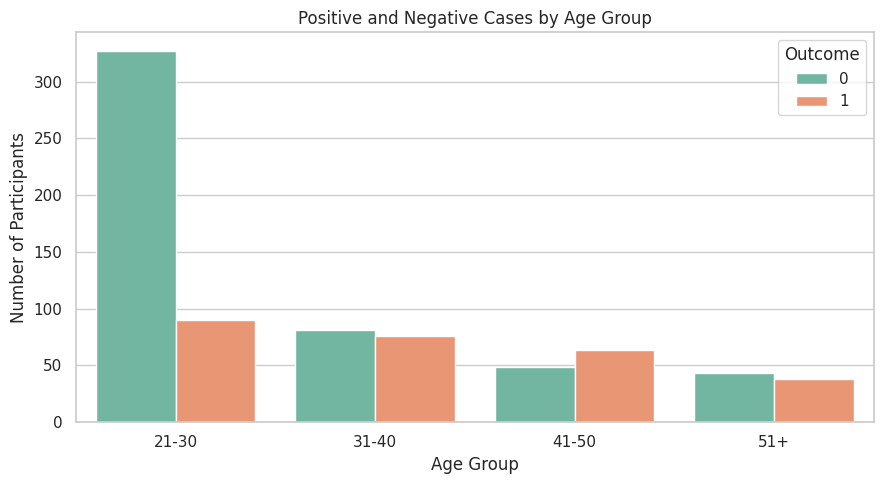

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=data_clean,
    x="Age_Group",
    hue="Outcome",
    palette="Set2"
)

plt.title("Positive and Negative Cases by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Participants")

plt.tight_layout()
plt.savefig(
    "results/figures/age_class_distribution.png",
    dpi=300
)
plt.show()

4. Feature distributions

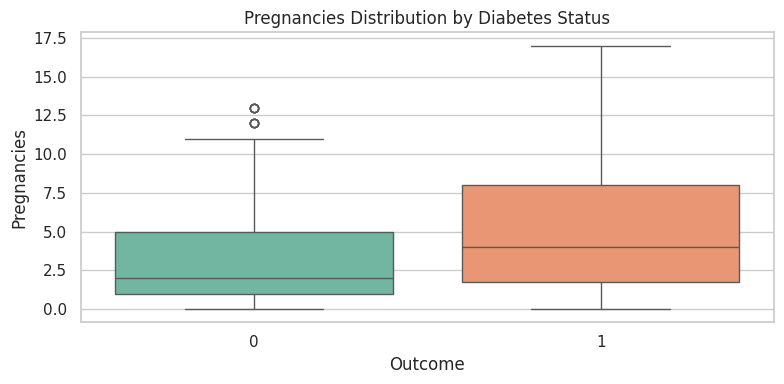

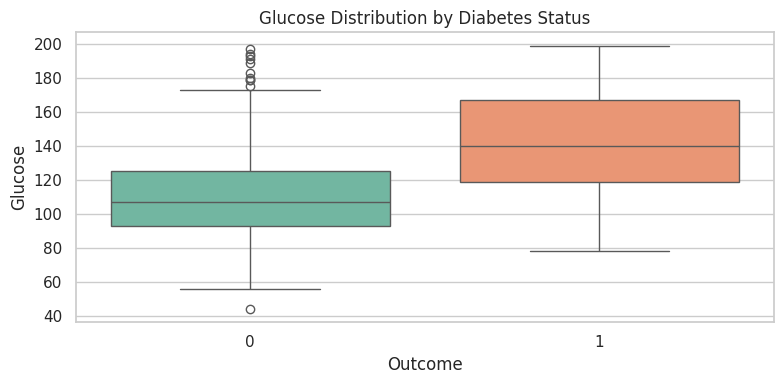

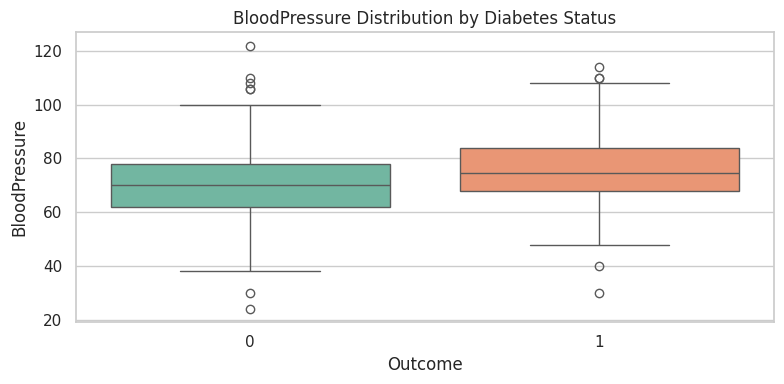

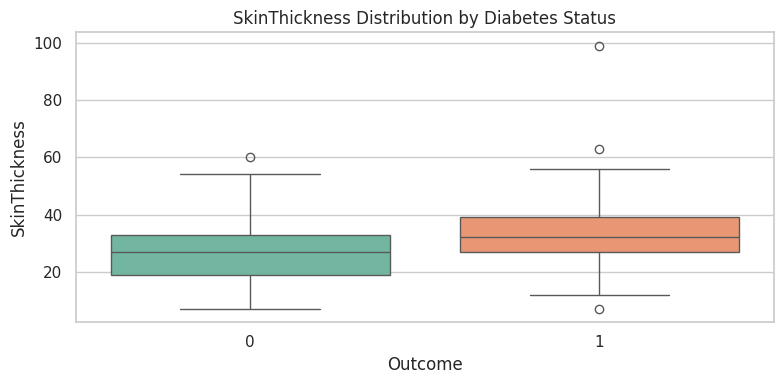

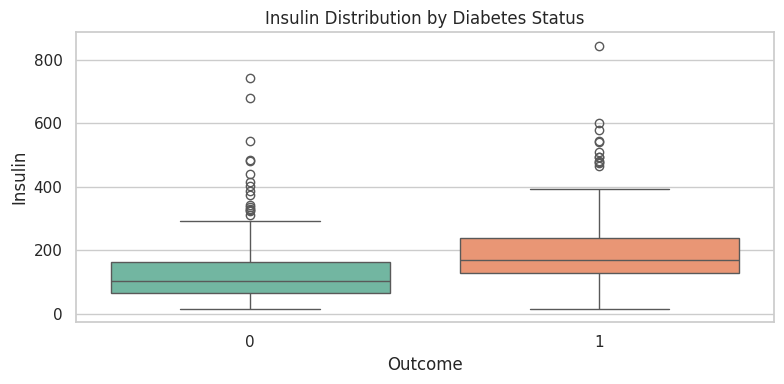

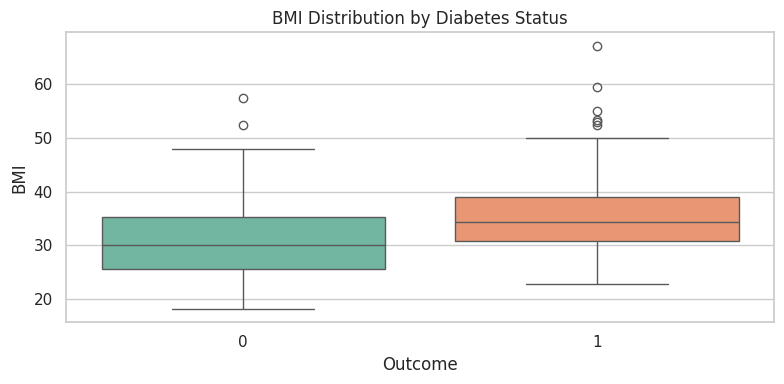

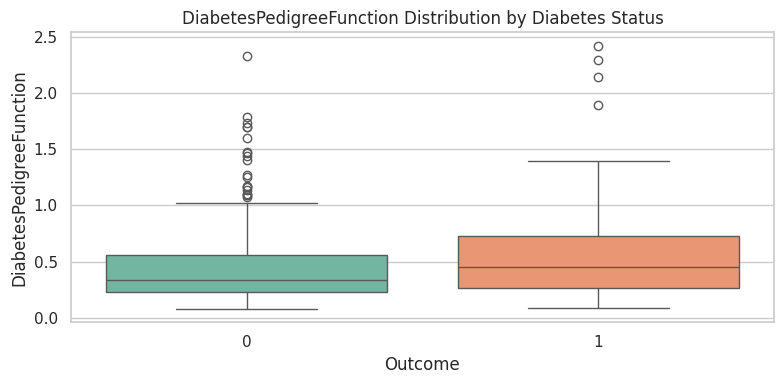

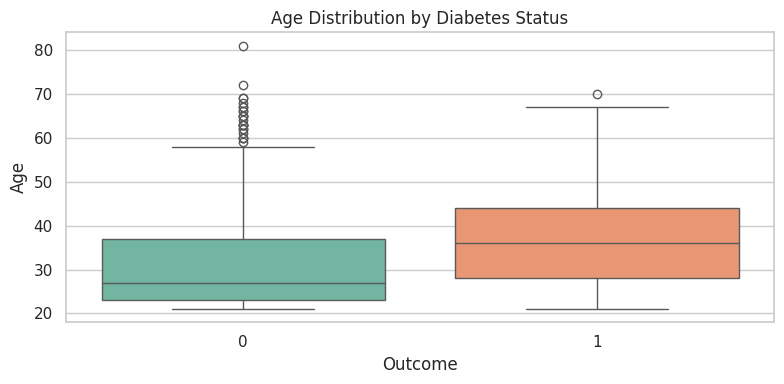

In [12]:
for col in FEATURES:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=data_clean,
        x="Outcome",
        y=col,
        hue="Outcome",
        palette="Set2",
        legend=False
    )

    plt.title(f"{col} Distribution by Diabetes Status")

    plt.tight_layout()

    plt.savefig(
        f"results/figures/{col}_distribution.png",
        dpi=300
    )

    plt.show()

5. Correlation heatmap

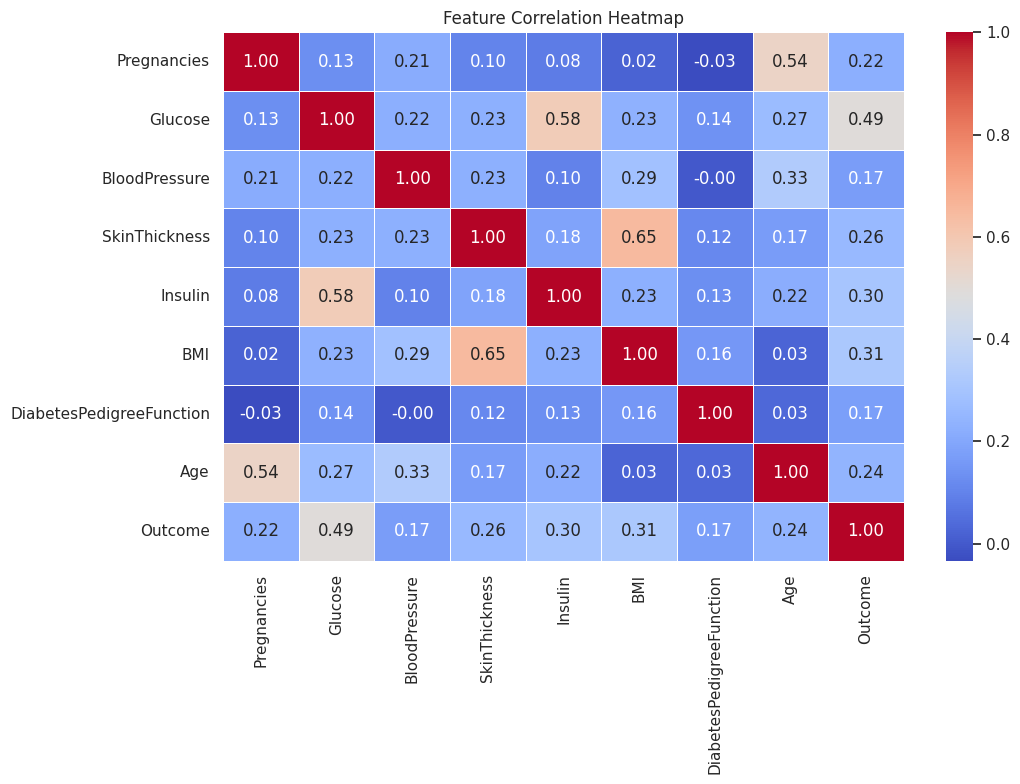

In [13]:
plt.figure(figsize=(11, 8))

corr = data_clean[FEATURES + ["Outcome"]].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.savefig(
    "results/figures/correlation_heatmap.png",
    dpi=300
)
plt.show()

Colab cell 7 — Age interaction investigation

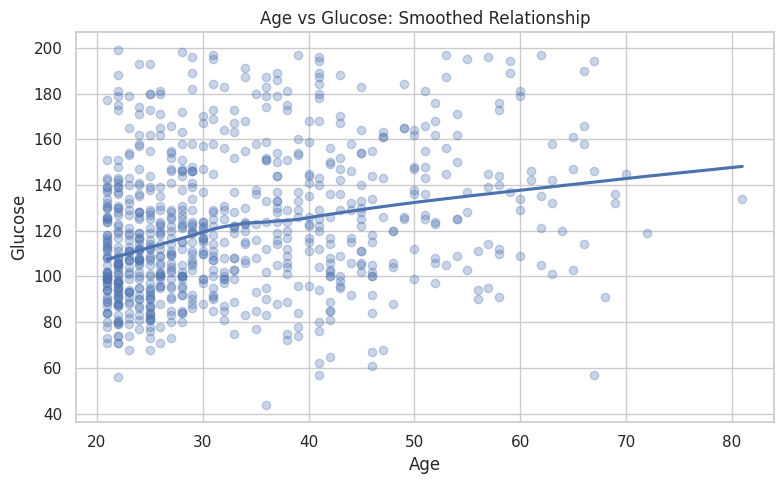

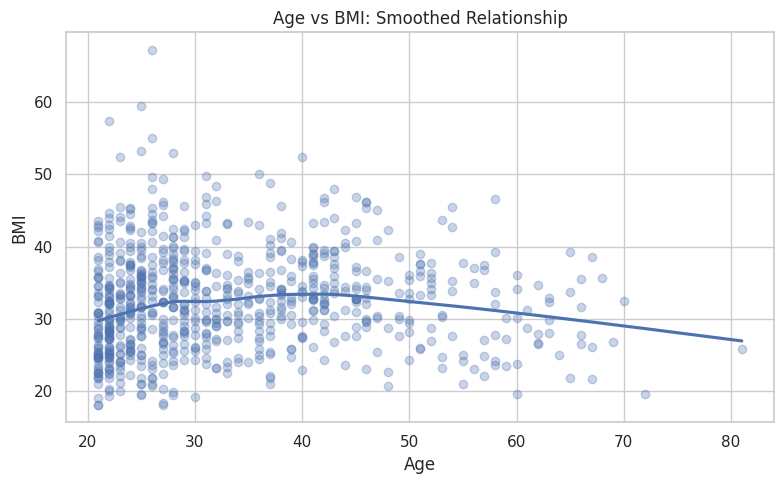

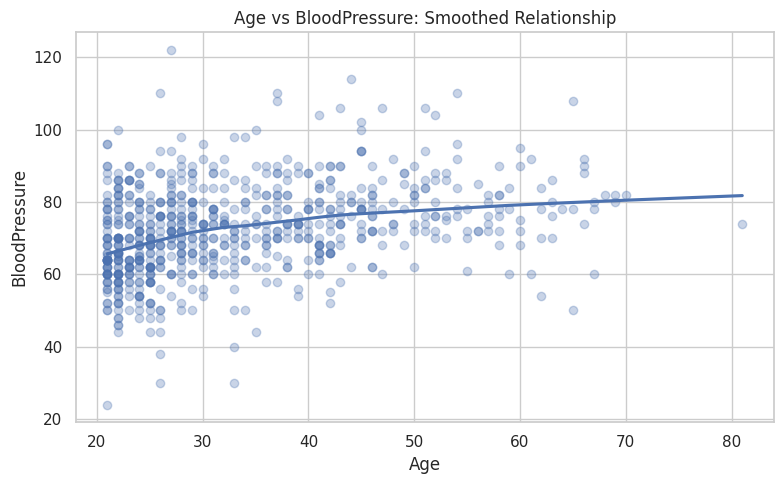

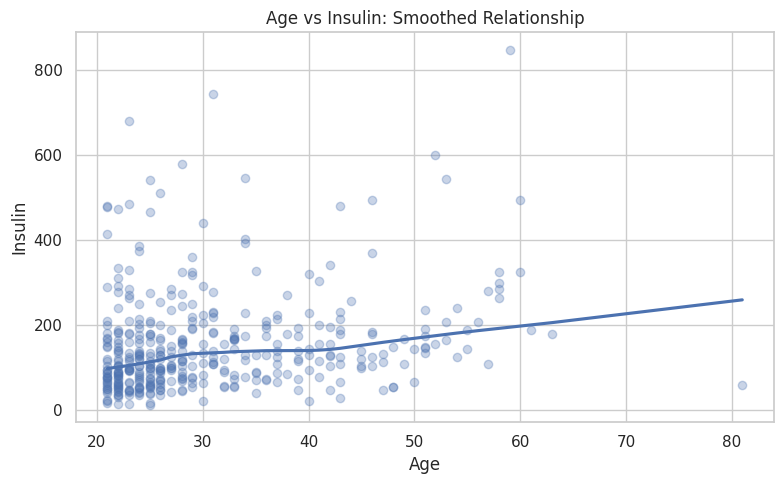

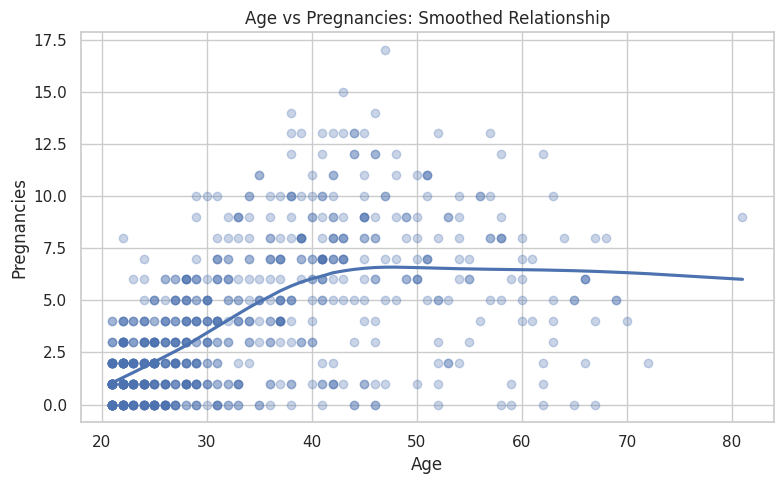

In [14]:
interaction_features = [
    "Glucose",
    "BMI",
    "BloodPressure",
    "Insulin",
    "Pregnancies"
]

for feature in interaction_features:

    plt.figure(figsize=(8, 5))

    sns.regplot(
        data=data_clean,
        x="Age",
        y=feature,
        scatter_kws={"alpha": 0.3},
        lowess=True
    )

    plt.title(
        f"Age vs {feature}: Smoothed Relationship"
    )

    plt.tight_layout()
    plt.show()

We will also investigate feature distributions by age and diabetes status.

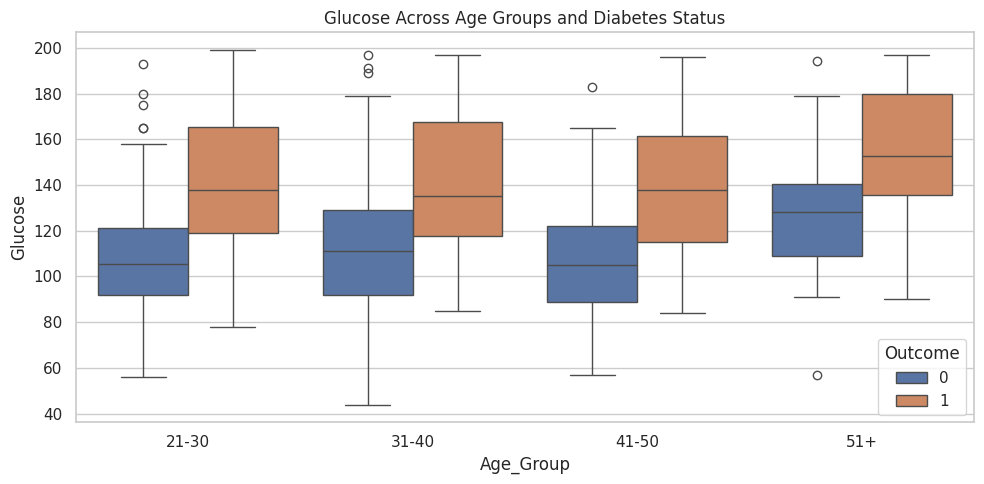

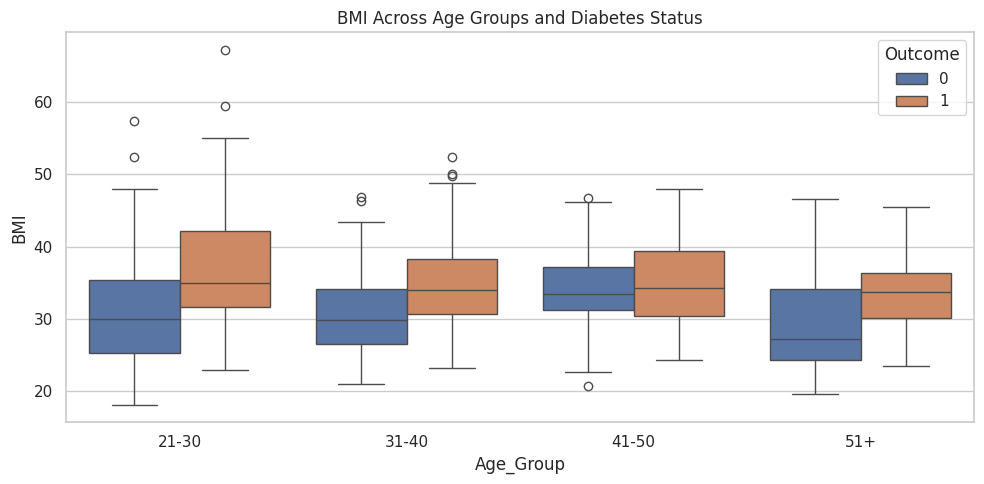

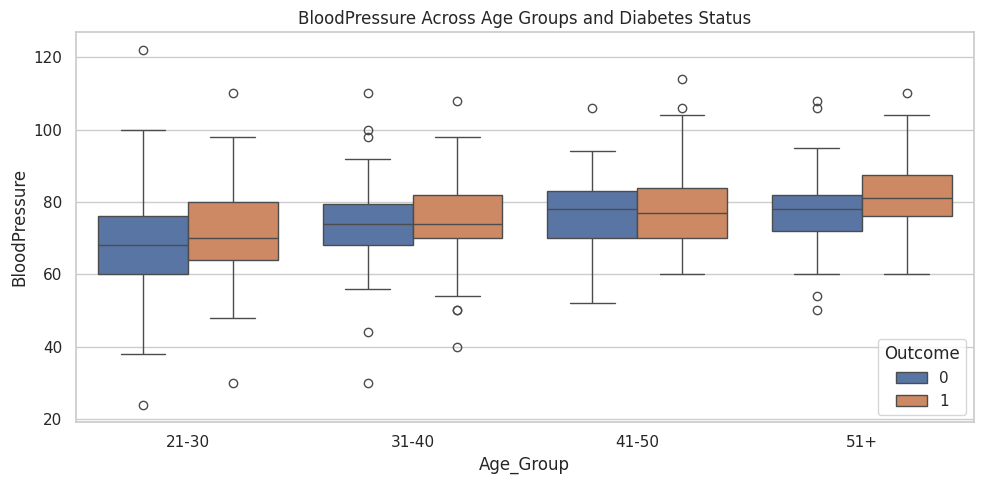

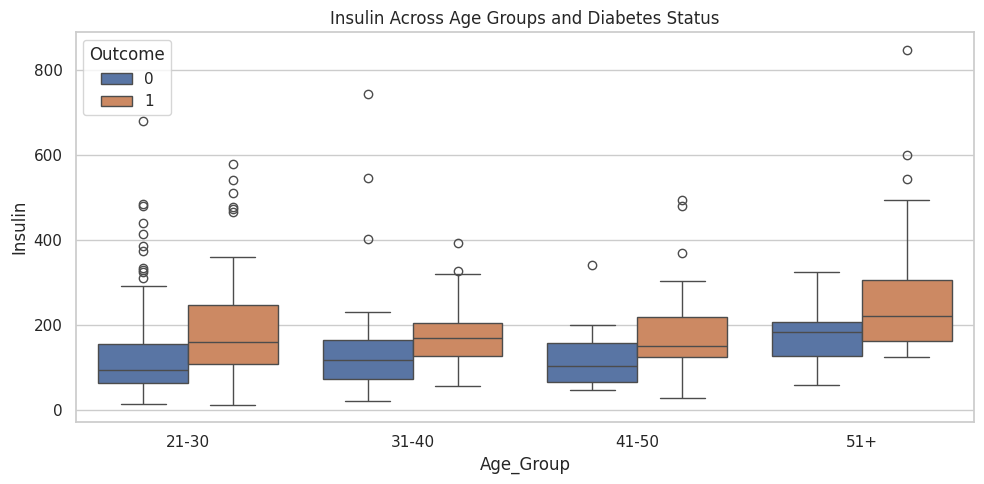

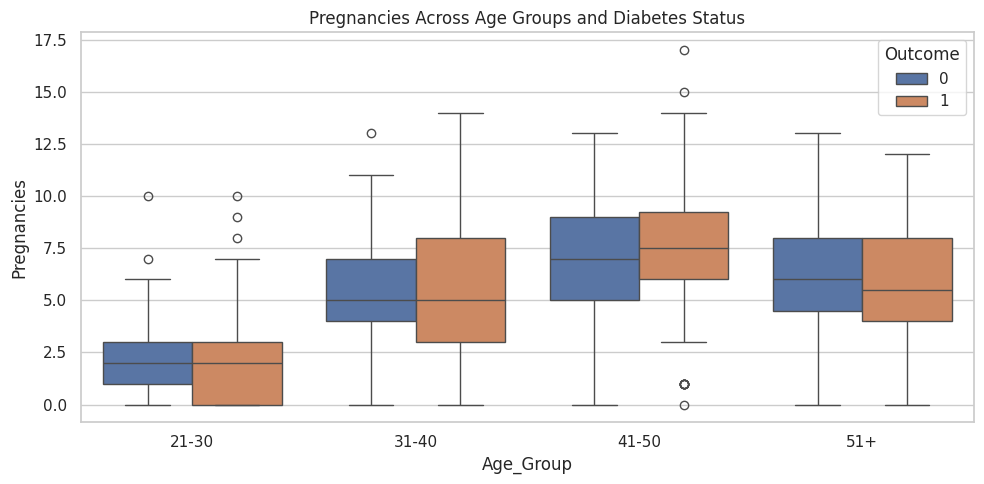

In [15]:
for feature in interaction_features:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=data_clean,
        x="Age_Group",
        y=feature,
        hue="Outcome"
    )

    plt.title(
        f"{feature} Across Age Groups and Diabetes Status"
    )

    plt.tight_layout()
    plt.show()

Colab cell 8 — Prepare the modeling dataset

In [16]:
X = data_clean[FEATURES].copy()
y = data_clean["Outcome"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nAge subgroup class counts:")

display(
    pd.crosstab(
        data_clean["Age_Group"],
        data_clean["Outcome"],
        margins=True
    )
)

# Confirm enough observations for stratified CV
if y.value_counts().min() < 5:
    raise ValueError(
        "Insufficient minority-class observations."
    )

print("\nModeling data prepared.")

X shape: (768, 8)
y shape: (768,)

Age subgroup class counts:


Outcome,0,1,All
Age_Group,,,
21-30,327,90,417
31-40,81,76,157
41-50,49,64,113
51+,43,38,81
All,500,268,768



Modeling data prepared.


# Part 2 — Model development

Colab cell 9 — Define preprocessing and baseline models

In [17]:
def make_pipeline(model, scale=False):

    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]

    if scale:
        steps.append(
            ("scaler", StandardScaler())
        )

    steps.append(("model", model))

    return Pipeline(steps)


# Model A: Global Bagging
global_bagging = make_pipeline(
    BaggingClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=5,
            random_state=SEED
        ),
        n_estimators=100,
        max_samples=0.8,
        max_features=1.0,
        bootstrap=True,
        n_jobs=-1,
        random_state=SEED
    )
)


# Model B: Local Bagging base estimator
local_bagging = make_pipeline(
    BaggingClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=5,
            random_state=SEED
        ),
        n_estimators=100,
        max_samples=0.8,
        bootstrap=True,
        n_jobs=-1,
        random_state=SEED
    )
)


# Benchmark models
baseline_models = {

    "Logistic Regression": make_pipeline(
        LogisticRegression(
            max_iter=2000,
            C=1.0,
            random_state=SEED
        ),
        scale=True
    ),

    "Decision Tree": make_pipeline(
        DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=5,
            random_state=SEED
        )
    ),

    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            min_samples_leaf=4,
            class_weight="balanced",
            n_jobs=-1,
            random_state=SEED
        )
    ),

    "Hist Gradient Boosting": make_pipeline(
        HistGradientBoostingClassifier(
            max_iter=100,
            max_leaf_nodes=10,
            l2_regularization=2.0,
            random_state=SEED
        )
    )
}

print("All model pipelines created.")

All model pipelines created.


Colab cell 10 — Age-specific local model functions

Here we train separate models for each age group.

However, we introduce a minimum sample requirement.

If an age group has insufficient data or only one outcome class, the local model will fall back to the global model.

In [18]:
MIN_GROUP_SIZE = 40
MIN_CLASS_COUNT = 5


def get_age_group(age):

    return pd.cut(
        pd.Series(age),
        bins=AGE_BINS,
        labels=AGE_LABELS,
        right=True,
        include_lowest=True
    )


def train_local_models(X_train, y_train):

    train_ages = X_train["Age"]

    groups = get_age_group(train_ages)

    local_models = {}

    for group in AGE_LABELS:

        mask = (
            groups.astype(str).values == group
        )

        X_group = X_train.loc[mask]
        y_group = y_train.loc[mask]

        counts = y_group.value_counts()

        if (
            len(X_group) >= MIN_GROUP_SIZE
            and counts.get(0, 0) >= MIN_CLASS_COUNT
            and counts.get(1, 0) >= MIN_CLASS_COUNT
        ):

            model = clone(local_bagging)

            model.fit(X_group, y_group)

            local_models[group] = model

    return local_models


def predict_local_models(
    X_test,
    global_model,
    local_models
):

    predictions = np.zeros(len(X_test))

    test_groups = get_age_group(
        X_test["Age"]
    )

    for i, group in enumerate(test_groups.astype(str)):

        if group in local_models:

            model = local_models[group]

        else:

            model = global_model

        row = X_test.iloc[[i]]

        predictions[i] = model.predict_proba(
            row
        )[0, 1]

    return predictions

# Colab cell 11 — Adaptive fusion mechanism
This is our main proposed method.

We will learn the fusion weights using out-of-fold predictions from the training data.

We are not going to use manually assigned 50:50 weights.
Mathematical concept
\[
\alpha(a)=\sigma(w_0+w_1z(a))
\]

\[
P_C=\alpha(a)P_G+(1-\alpha(a))P_L
\]

Where \(z(a)\) is standardized age

In [19]:
def fit_adaptive_gate(
    y_train,
    global_oof,
    local_oof,
    ages
):

    y_array = np.asarray(y_train)

    p_global = np.clip(
        np.asarray(global_oof),
        1e-6,
        1 - 1e-6
    )

    p_local = np.clip(
        np.asarray(local_oof),
        1e-6,
        1 - 1e-6
    )

    age_mean = np.mean(ages)
    age_std = np.std(ages) + 1e-8

    age_scaled = (
        np.asarray(ages) - age_mean
    ) / age_std

    def objective(params):

        w0, w1 = params

        alpha = expit(
            w0 + w1 * age_scaled
        )

        final_probability = (
            alpha * p_global
            + (1 - alpha) * p_local
        )

        final_probability = np.clip(
            final_probability,
            1e-6,
            1 - 1e-6
        )

        loss = log_loss(
            y_array,
            final_probability,
            labels=[0, 1]
        )

        regularization = (
            0.01 * (w0**2 + w1**2)
        )

        return loss + regularization

    result = minimize(
        objective,
        x0=np.array([0.0, 0.0]),
        method="L-BFGS-B",
        bounds=[(-5, 5), (-5, 5)]
    )

    return {
        "w0": result.x[0],
        "w1": result.x[1],
        "age_mean": age_mean,
        "age_std": age_std,
        "success": result.success
    }


def apply_adaptive_gate(
    gate,
    p_global,
    p_local,
    ages
):

    age_scaled = (
        np.asarray(ages) - gate["age_mean"]
    ) / gate["age_std"]

    alpha = expit(
        gate["w0"] +
        gate["w1"] * age_scaled
    )

    final_probability = (
        alpha * np.asarray(p_global)
        + (1 - alpha) * np.asarray(p_local)
    )

    return (
        final_probability,
        alpha
    )

# Colab cell 12 — Generate out-of-fold predictions
This function is critical.

We train global and local models on internal training folds and predict the held-out fold.

These predictions are used to train the adaptive fusion gate.

In [20]:
def generate_oof_predictions(
    X_train,
    y_train,
    n_splits=4
):

    oof_global = np.zeros(len(X_train))
    oof_local = np.zeros(len(X_train))

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED
    )

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train),
        start=1
    ):

        X_inner_train = X_train.iloc[train_idx]
        X_inner_val = X_train.iloc[val_idx]

        y_inner_train = y_train.iloc[train_idx]

        # Global model
        global_model = clone(global_bagging)

        global_model.fit(
            X_inner_train,
            y_inner_train
        )

        oof_global[val_idx] = (
            global_model.predict_proba(
                X_inner_val
            )[:, 1]
        )

        # Local models
        local_models = train_local_models(
            X_inner_train,
            y_inner_train
        )

        oof_local[val_idx] = (
            predict_local_models(
                X_inner_val,
                global_model,
                local_models
            )
        )

        print(
            f"OOF fold {fold}/{n_splits} completed"
        )

    return oof_global, oof_local

# Colab cell 12 — Generate out-of-fold predictions
This function is critical.

We train global and local models on internal training folds and predict the held-out fold.

These predictions are used to train the adaptive fusion gate.

In [21]:
def generate_oof_predictions(
    X_train,
    y_train,
    n_splits=4
):

    oof_global = np.zeros(len(X_train))
    oof_local = np.zeros(len(X_train))

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED
    )

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train),
        start=1
    ):

        X_inner_train = X_train.iloc[train_idx]
        X_inner_val = X_train.iloc[val_idx]

        y_inner_train = y_train.iloc[train_idx]

        # Global model
        global_model = clone(global_bagging)

        global_model.fit(
            X_inner_train,
            y_inner_train
        )

        oof_global[val_idx] = (
            global_model.predict_proba(
                X_inner_val
            )[:, 1]
        )

        # Local models
        local_models = train_local_models(
            X_inner_train,
            y_inner_train
        )

        oof_local[val_idx] = (
            predict_local_models(
                X_inner_val,
                global_model,
                local_models
            )
        )

        print(
            f"OOF fold {fold}/{n_splits} completed"
        )

    return oof_global, oof_local

# Colab cell 13 — Fixed and adaptive fusion
We will compare:
- Global Bagging.
- Local Bagging.
- Fixed 50:50 fusion.
- Learned constant fusion.
- Age-dependent adaptive fusion.

In [22]:
def fit_constant_gate(
    y_train,
    p_global,
    p_local
):

    y_array = np.asarray(y_train)

    p_global = np.clip(
        p_global, 1e-6, 1 - 1e-6
    )

    p_local = np.clip(
        p_local, 1e-6, 1 - 1e-6
    )

    def objective(params):

        alpha = expit(params[0])

        p = (
            alpha * p_global
            + (1 - alpha) * p_local
        )

        return log_loss(
            y_array,
            np.clip(p, 1e-6, 1 - 1e-6),
            labels=[0, 1]
        )

    result = minimize(
        objective,
        x0=[0.0],
        method="L-BFGS-B"
    )

    return expit(result.x[0])

Colab cell 14 — Define performance metrics

In [23]:
def calculate_metrics(y_true, probabilities):

    probabilities = np.clip(
        np.asarray(probabilities),
        1e-6,
        1 - 1e-6
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "Sensitivity": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "Specificity": specificity,

        "F1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "ROC_AUC": (
            roc_auc_score(y_true, probabilities)
            if len(np.unique(y_true)) == 2
            else np.nan
        ),

        "PR_AUC": (
            average_precision_score(
                y_true, probabilities
            )
            if len(np.unique(y_true)) == 2
            else np.nan
        ),

        "Brier_Score": brier_score_loss(
            y_true, probabilities
        ),

        "Log_Loss": log_loss(
            y_true,
            probabilities,
            labels=[0, 1]
        )
    }

# Part 3 — Cross-validation and experimental comparison

Colab cell 15 — Nested model tuning
We will tune the global Bagging model using only the outer training data.

The outer test fold will remain untouched.

In [24]:
def tune_global_model(X_train, y_train):

    parameter_space = {

        "model__n_estimators": [
            50, 100, 150, 200
        ],

        "model__estimator__max_depth": [
            2, 3, 4, 5, 6
        ],

        "model__estimator__min_samples_leaf": [
            3, 5, 8, 10
        ],

        "model__max_samples": [
            0.7, 0.8, 0.9, 1.0
        ]
    }

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=SEED
    )

    search = RandomizedSearchCV(
        estimator=global_bagging,
        param_distributions=parameter_space,
        n_iter=6,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        random_state=SEED,
        refit=True
    )

    search.fit(X_train, y_train)

    print("Best parameters:", search.best_params_)
    print("Best inner CV ROC-AUC:", search.best_score_)

    return search.best_estimator_

For cross-fitted gate training, we will use the tuned estimator as the global-model template.

In [25]:
def generate_oof_predictions_tuned(
    X_train,
    y_train,
    global_estimator,
    n_splits=4
):

    oof_global = np.zeros(len(X_train))
    oof_local = np.zeros(len(X_train))

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED + 10
    )

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train),
        start=1
    ):

        X_inner_train = X_train.iloc[train_idx]
        X_inner_val = X_train.iloc[val_idx]

        y_inner_train = y_train.iloc[train_idx]

        # Global
        global_model = clone(global_estimator)

        global_model.fit(
            X_inner_train,
            y_inner_train
        )

        oof_global[val_idx] = (
            global_model.predict_proba(
                X_inner_val
            )[:, 1]
        )

        # Local
        local_models = train_local_models(
            X_inner_train,
            y_inner_train
        )

        oof_local[val_idx] = (
            predict_local_models(
                X_inner_val,
                global_model,
                local_models
            )
        )

        print(
            f"Tuned OOF fold {fold}/{n_splits} completed"
        )

    return oof_global, oof_local

Colab cell 16 — Main experimental evaluation

We now execute the complete experimental comparison.

Outer five-fold stratified cross-validation will be used.

Each participant receives an out-of-fold prediction from a model that did not train on that participant.

In [26]:
OUTER_SPLITS = 5

outer_cv = StratifiedKFold(
    n_splits=OUTER_SPLITS,
    shuffle=True,
    random_state=SEED
)

model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Hist Gradient Boosting",
    "Global Bagging",
    "Local Bagging",
    "Fixed Fusion",
    "Learned Constant Fusion",
    "Adaptive Fusion"
]

oof_predictions = {
    name: np.zeros(len(X))
    for name in model_names
}

oof_alpha = np.zeros(len(X))

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 60)
    print(f"OUTER FOLD {fold}/{OUTER_SPLITS}")
    print("=" * 60)

    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx].copy()
    y_test = y.iloc[test_idx].copy()

    # ----------------------------------
    # 1. Tune global bagging
    # ----------------------------------

    tuned_global = tune_global_model(
        X_train,
        y_train
    )

    # ----------------------------------
    # 2. Cross-fitted training predictions
    # ----------------------------------

    oof_global, oof_local = (
        generate_oof_predictions_tuned(
            X_train,
            y_train,
            tuned_global
        )
    )

    # ----------------------------------
    # 3. Train adaptive fusion gate
    # ----------------------------------

    gate = fit_adaptive_gate(
        y_train,
        oof_global,
        oof_local,
        X_train["Age"].values
    )

    # ----------------------------------
    # 4. Train final global model
    # ----------------------------------

    tuned_global.fit(
        X_train,
        y_train
    )

    p_global = tuned_global.predict_proba(
        X_test
    )[:, 1]

    # ----------------------------------
    # 5. Train local models
    # ----------------------------------

    local_models = train_local_models(
        X_train,
        y_train
    )

    p_local = predict_local_models(
        X_test,
        tuned_global,
        local_models
    )

    # ----------------------------------
    # 6. Generate fusion predictions
    # ----------------------------------

    p_fixed = (
        0.5 * p_global
        + 0.5 * p_local
    )

    constant_alpha = fit_constant_gate(
        y_train,
        oof_global,
        oof_local
    )

    p_constant = (
        constant_alpha * p_global
        + (1 - constant_alpha) * p_local
    )

    p_adaptive, alpha = apply_adaptive_gate(
        gate,
        p_global,
        p_local,
        X_test["Age"].values
    )

    # ----------------------------------
    # 7. Store Model A, B, C
    # ----------------------------------

    oof_predictions["Global Bagging"][test_idx] = (
        p_global
    )

    oof_predictions["Local Bagging"][test_idx] = (
        p_local
    )

    oof_predictions["Fixed Fusion"][test_idx] = (
        p_fixed
    )

    oof_predictions["Learned Constant Fusion"][test_idx] = (
        p_constant
    )

    oof_predictions["Adaptive Fusion"][test_idx] = (
        p_adaptive
    )

    oof_alpha[test_idx] = alpha

    # ----------------------------------
    # 8. Baseline models
    # ----------------------------------

    for name, model_template in baseline_models.items():

        model = clone(model_template)

        model.fit(
            X_train,
            y_train
        )

        probabilities = model.predict_proba(
            X_test
        )[:, 1]

        oof_predictions[name][test_idx] = (
            probabilities
        )

    # ----------------------------------
    # 9. Fold-level evaluation
    # ----------------------------------

    for name in model_names:

        metrics = calculate_metrics(
            y_test,
            oof_predictions[name][test_idx]
        )

        metrics["Fold"] = fold
        metrics["Model"] = name

        fold_results.append(metrics)

    print(
        "Available local models:",
        list(local_models.keys())
    )

    print(
        "Adaptive gate parameters:",
        gate
    )

    print(
        "Learned constant alpha:",
        constant_alpha
    )

print("\nAll outer folds completed.")


OUTER FOLD 1/5
Best parameters: {'model__n_estimators': 150, 'model__max_samples': 0.8, 'model__estimator__min_samples_leaf': 8, 'model__estimator__max_depth': 5}
Best inner CV ROC-AUC: 0.8065526498141038
Tuned OOF fold 1/4 completed
Tuned OOF fold 2/4 completed
Tuned OOF fold 3/4 completed
Tuned OOF fold 4/4 completed
Available local models: ['21-30', '31-40', '41-50', '51+']
Adaptive gate parameters: {'w0': np.float64(0.07017344536524885), 'w1': np.float64(-0.009782112037683172), 'age_mean': np.float64(33.02117263843648), 'age_std': np.float64(11.612831615956695), 'success': True}
Learned constant alpha: 0.614980496785545

OUTER FOLD 2/5
Best parameters: {'model__n_estimators': 150, 'model__max_samples': 0.8, 'model__estimator__min_samples_leaf': 8, 'model__estimator__max_depth': 5}
Best inner CV ROC-AUC: 0.8232210682851292
Tuned OOF fold 1/4 completed
Tuned OOF fold 2/4 completed
Tuned OOF fold 3/4 completed
Tuned OOF fold 4/4 completed
Available local models: ['21-30', '31-40', '4

Colab cell 17 — Overall performance comparison

In [27]:
overall_results = []

for name in model_names:

    metrics = calculate_metrics(
        y,
        oof_predictions[name]
    )

    metrics["Model"] = name

    overall_results.append(metrics)

results_df = pd.DataFrame(overall_results)

results_df = results_df[
    ["Model"] +
    [col for col in results_df.columns if col != "Model"]
]

results_df = results_df.sort_values(
    "ROC_AUC",
    ascending=False
)

print("OVERALL MODEL COMPARISON")

display(
    results_df.style.format({
        col: "{:.4f}"
        for col in results_df.columns
        if col != "Model"
    })
)

results_df.to_csv(
    "results/tables/overall_model_comparison.csv",
    index=False
)

fold_results_df = pd.DataFrame(fold_results)

fold_results_df.to_csv(
    "results/tables/fold_results.csv",
    index=False
)

OVERALL MODEL COMPARISON


,Model,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
2,Random Forest,0.7669,0.6386,0.7649,0.7680,0.6961,0.8363,0.6957,0.1622,0.4914
4,Global Bagging,0.7630,0.6853,0.5933,0.8540,0.6360,0.8345,0.6952,0.1564,0.4740
7,Learned Constant Fusion,0.7630,0.6838,0.5970,0.8520,0.6375,0.8345,0.6956,0.1564,0.4745
0,Logistic Regression,0.7682,0.7083,0.5709,0.8740,0.6322,0.8340,0.7088,0.1571,0.4790
8,Adaptive Fusion,0.7617,0.6856,0.5858,0.8560,0.6318,0.8323,0.6911,0.1570,0.4774
6,Fixed Fusion,0.7591,0.6812,0.5821,0.8540,0.6278,0.8313,0.6886,0.1573,0.4785
5,Local Bagging,0.7747,0.7039,0.6119,0.8620,0.6547,0.8190,0.6691,0.1633,0.4976
3,Hist Gradient Boosting,0.7578,0.6640,0.6194,0.8320,0.6409,0.8150,0.6632,0.1700,0.5259
1,Decision Tree,0.7279,0.6014,0.6530,0.7680,0.6261,0.7735,0.6026,0.1886,0.7519


Colab cell 18 — Compare the three primary models

,Model,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
4,Global Bagging,0.763021,0.685345,0.593284,0.854,0.636000,0.834530,0.695153,0.156374,0.474017
8,Adaptive Fusion,0.761719,0.685590,0.585821,0.856,0.631791,0.832254,0.691089,0.156972,0.477425
5,Local Bagging,0.774740,0.703863,0.611940,0.862,0.654691,0.818970,0.669121,0.163261,0.497558


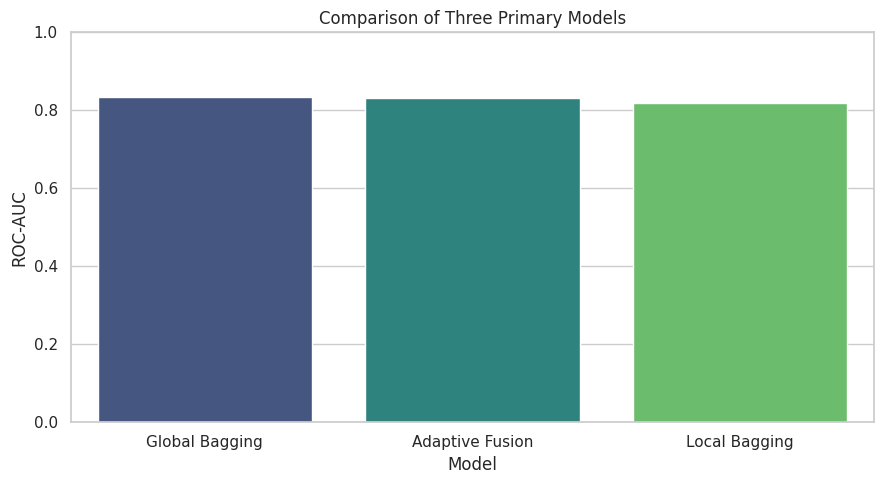

In [28]:
primary_models = [
    "Global Bagging",
    "Local Bagging",
    "Adaptive Fusion"
]

primary_results = results_df[
    results_df["Model"].isin(primary_models)
].copy()

display(primary_results)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=primary_results,
    x="Model",
    y="ROC_AUC",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Comparison of Three Primary Models")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(
    "results/figures/three_model_comparison.png",
    dpi=300
)

plt.show()

Colab cell 19 — ROC curves

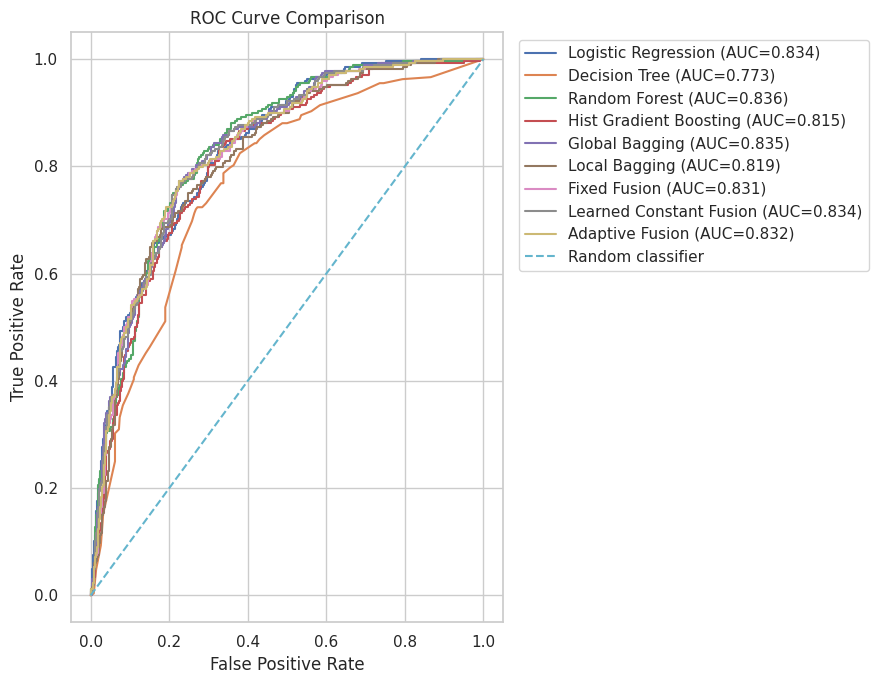

In [29]:
plt.figure(figsize=(9, 7))

for name in model_names:

    probabilities = oof_predictions[name]

    fpr, tpr, _ = roc_curve(
        y,
        probabilities
    )

    auc_value = roc_auc_score(
        y,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "results/figures/roc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Colab cell 20 — Precision-recall curves

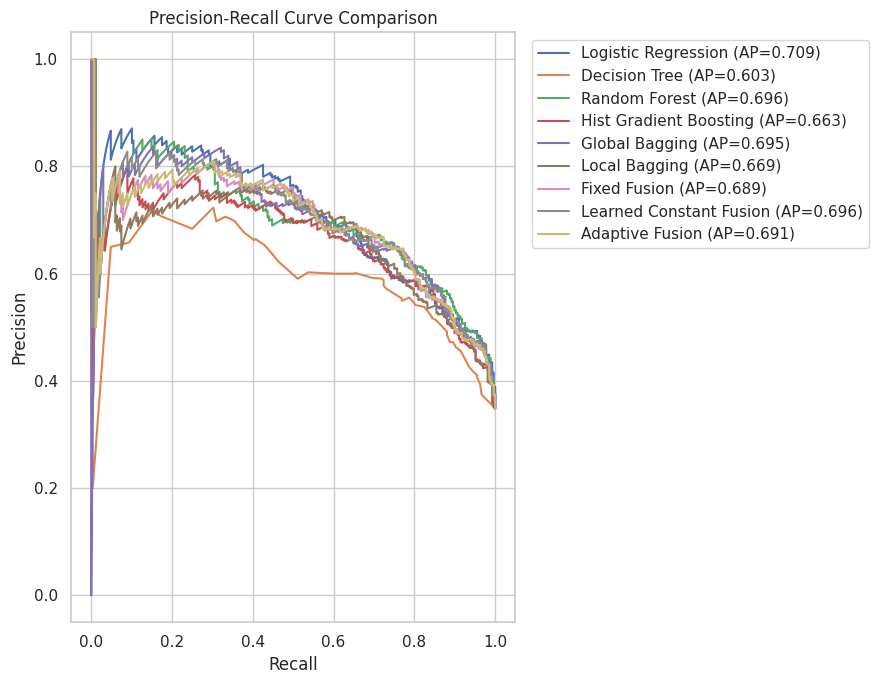

In [30]:
plt.figure(figsize=(9, 7))

for name in model_names:

    precision, recall, _ = (
        precision_recall_curve(
            y,
            oof_predictions[name]
        )
    )

    ap = average_precision_score(
        y,
        oof_predictions[name]
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve Comparison")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "results/figures/pr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Part 4 — Age-based performance analysis

Colab cell 21 — Subgroup performance

In [31]:
subgroup_results = []

for group in AGE_LABELS:

    mask = (
        get_age_group(X["Age"]).astype(str).values
        == group
    )

    y_group = y.iloc[np.where(mask)[0]]

    if len(y_group) == 0:
        continue

    for model_name in model_names:

        p_group = oof_predictions[model_name][mask]

        metrics = calculate_metrics(
            y_group,
            p_group
        )

        metrics["Age_Group"] = group
        metrics["Model"] = model_name
        metrics["Sample_Size"] = len(y_group)
        metrics["Positive_Cases"] = int(y_group.sum())

        subgroup_results.append(metrics)

subgroup_df = pd.DataFrame(subgroup_results)

display(subgroup_df)

subgroup_df.to_csv(
    "results/tables/subgroup_performance.csv",
    index=False
)

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Age_Group,Model,Sample_Size,Positive_Cases
0,0.836930,0.683333,0.455556,0.941896,0.546667,0.853551,0.651373,0.117856,0.373392,21-30,Logistic Regression,417,90
1,0.791367,0.517241,0.500000,0.871560,0.508475,0.750119,0.503002,0.153202,0.616519,21-30,Decision Tree,417,90
2,0.798561,0.531250,0.566667,0.862385,0.548387,0.836323,0.607937,0.132036,0.414165,21-30,Random Forest,417,90
3,0.815348,0.597015,0.444444,0.917431,0.509554,0.796398,0.539014,0.137045,0.443293,21-30,Hist Gradient Boosting,417,90
4,0.822542,0.642857,0.400000,0.938838,0.493151,0.832790,0.621351,0.122466,0.384537,21-30,Global Bagging,417,90
5,0.832134,0.727273,0.355556,0.963303,0.477612,0.815664,0.598832,0.127962,0.402483,21-30,Local Bagging,417,90
6,0.820144,0.647059,0.366667,0.944954,0.468085,0.826809,0.608475,0.124135,0.389738,21-30,Fixed Fusion,417,90
7,0.822542,0.642857,0.400000,0.938838,0.493151,0.830717,0.620655,0.123284,0.386732,21-30,Learned Constant Fusion,417,90
8,0.820144,0.647059,0.366667,0.944954,0.468085,0.827455,0.609033,0.124003,0.389250,21-30,Adaptive Fusion,417,90
9,0.700637,0.745763,0.578947,0.814815,0.651852,0.779890,0.735369,0.195165,0.587864,31-40,Logistic Regression,157,76


Colab cell 22 — Age-wise ROC-AUC comparison

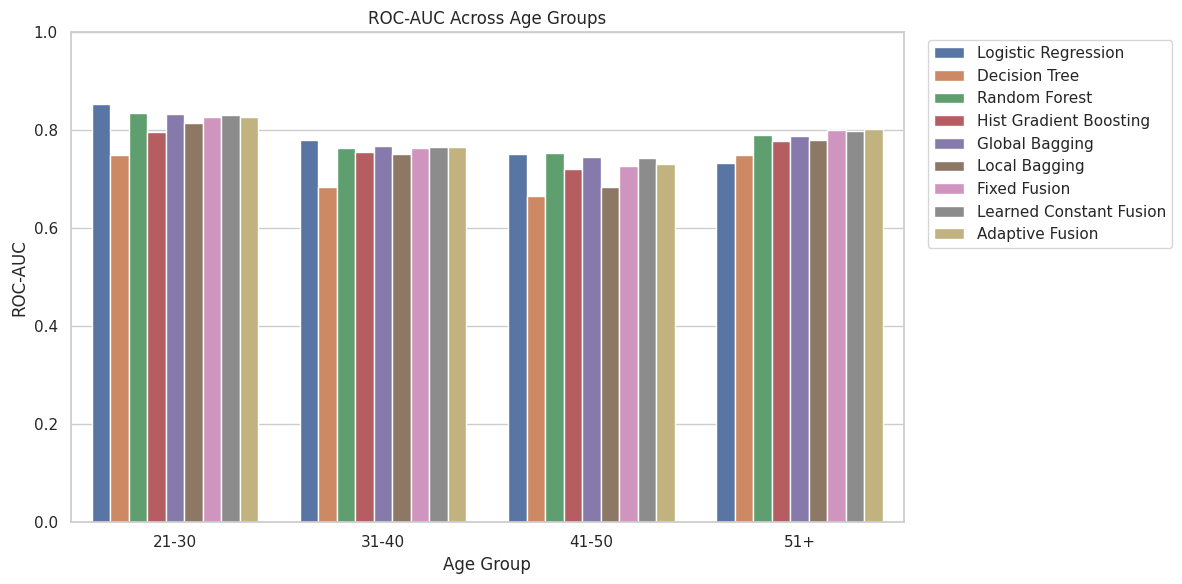

In [32]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=subgroup_df,
    x="Age_Group",
    y="ROC_AUC",
    hue="Model"
)

plt.title("ROC-AUC Across Age Groups")

plt.xlabel("Age Group")
plt.ylabel("ROC-AUC")

plt.ylim(0, 1)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "results/figures/subgroup_auc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Colab cell 23 — Sensitivity and specificity by age

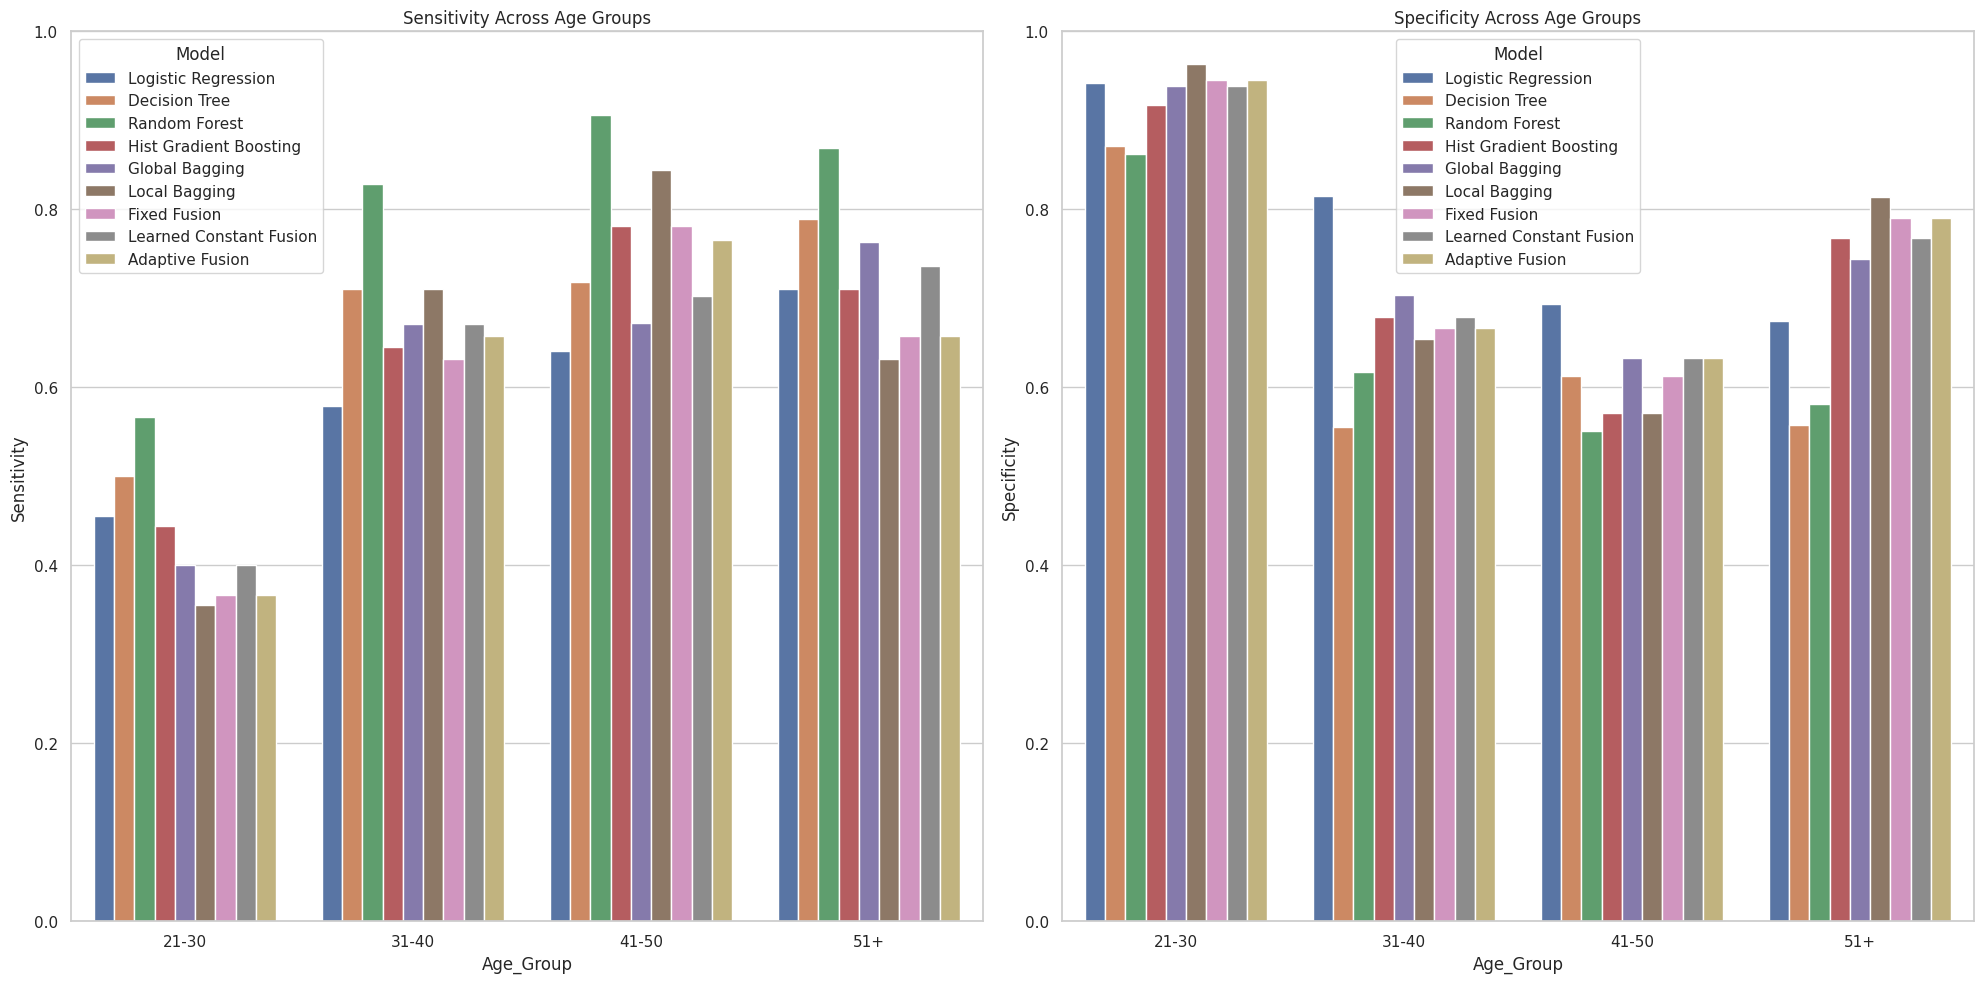

In [33]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 10)
)

sns.barplot(
    data=subgroup_df,
    x="Age_Group",
    y="Sensitivity",
    hue="Model",
    ax=axes[0]
)

axes[0].set_title(
    "Sensitivity Across Age Groups"
)

sns.barplot(
    data=subgroup_df,
    x="Age_Group",
    y="Specificity",
    hue="Model",
    ax=axes[1]
)

axes[1].set_title(
    "Specificity Across Age Groups"
)

for ax in axes:
    ax.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "results/figures/age_sensitivity_specificity.png",
    dpi=300
)

plt.show()

Colab cell 24 — Adaptive gate visualization
This visualization helps us understand how the global and local contributions change with age.

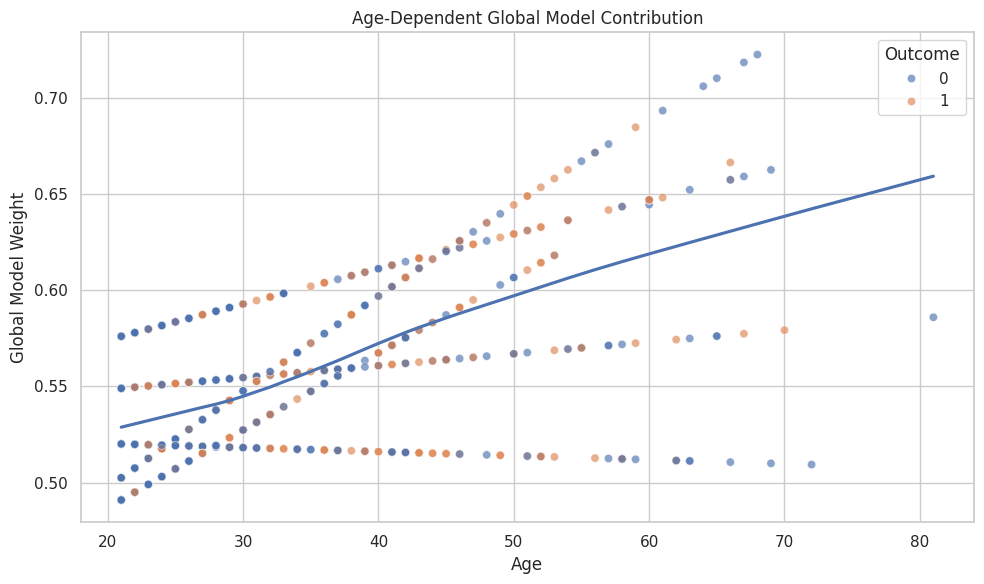

Mean global contribution: 0.5540279729027046
Mean local contribution: 0.4459720270972955


In [34]:
gate_df = pd.DataFrame({
    "Age": X["Age"].values,
    "Global_Weight": oof_alpha,
    "Local_Weight": 1 - oof_alpha,
    "Outcome": y.values
})

gate_df = gate_df.sort_values("Age")

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=gate_df,
    x="Age",
    y="Global_Weight",
    hue="Outcome",
    alpha=0.65
)

sns.regplot(
    data=gate_df,
    x="Age",
    y="Global_Weight",
    scatter=False,
    lowess=True
)

plt.title(
    "Age-Dependent Global Model Contribution"
)

plt.xlabel("Age")
plt.ylabel("Global Model Weight")

plt.tight_layout()

plt.savefig(
    "results/figures/adaptive_gate.png",
    dpi=300
)

plt.show()

print(
    "Mean global contribution:",
    np.mean(oof_alpha)
)

print(
    "Mean local contribution:",
    np.mean(1 - oof_alpha)
)

Colab cell 25 — Age-related performance gaps

In [35]:
gap_results = []

for model_name in model_names:

    temp = subgroup_df[
        subgroup_df["Model"] == model_name
    ]

    result = {
        "Model": model_name
    }

    for metric in [
        "ROC_AUC",
        "Sensitivity",
        "Specificity",
        "F1",
        "Brier_Score"
    ]:

        values = temp[metric].dropna()

        if len(values) >= 2:

            result[f"{metric}_Gap"] = (
                values.max() - values.min()
            )

        else:

            result[f"{metric}_Gap"] = np.nan

    gap_results.append(result)

gap_df = pd.DataFrame(gap_results)

display(gap_df)

gap_df.to_csv(
    "results/tables/age_performance_gaps.csv",
    index=False
)

,Model,ROC_AUC_Gap,Sensitivity_Gap,Specificity_Gap,F1_Gap,Brier_Score_Gap
0,Logistic Regression,0.119769,0.254971,0.267477,0.136878,0.098657
1,Decision Tree,0.084462,0.289474,0.316004,0.204704,0.089058
2,Random Forest,0.082497,0.339583,0.311365,0.257168,0.069184
3,Hist Gradient Boosting,0.074459,0.336806,0.346003,0.231187,0.083311
4,Global Bagging,0.086297,0.363158,0.306185,0.250439,0.081404
5,Local Bagging,0.130715,0.488194,0.391874,0.299366,0.091374
6,Fixed Fusion,0.098812,0.414583,0.332709,0.283795,0.081791
7,Learned Constant Fusion,0.086776,0.336842,0.306185,0.243691,0.080039
8,Adaptive Fusion,0.095312,0.398958,0.312301,0.280006,0.080578


# Part 5 — Statistical validation
Colab cell 26 — Bootstrap confidence intervals
We will calculate participant-level bootstrap confidence intervals for overall performance.

In [36]:
def bootstrap_ci(
    y_true,
    probabilities,
    metric_name="ROC_AUC",
    n_bootstrap=2000,
    confidence=0.95,
    seed=42
):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    rng = np.random.default_rng(seed)

    values = []

    for _ in range(n_bootstrap):

        indices = rng.integers(
            0,
            len(y_true),
            len(y_true)
        )

        y_sample = y_true[indices]
        p_sample = probabilities[indices]

        if len(np.unique(y_sample)) < 2:
            continue

        metrics = calculate_metrics(
            y_sample,
            p_sample
        )

        value = metrics.get(metric_name)

        if np.isfinite(value):
            values.append(value)

    lower = np.quantile(
        values,
        (1 - confidence) / 2
    )

    upper = np.quantile(
        values,
        1 - (1 - confidence) / 2
    )

    return lower, upper

In [37]:
ci_results = []

for name in model_names:

    for metric in [
        "ROC_AUC",
        "PR_AUC",
        "Sensitivity",
        "Specificity",
        "Brier_Score"
    ]:

        point_estimate = calculate_metrics(
            y,
            oof_predictions[name]
        )[metric]

        lower, upper = bootstrap_ci(
            y,
            oof_predictions[name],
            metric_name=metric
        )

        ci_results.append({

            "Model": name,
            "Metric": metric,
            "Estimate": point_estimate,
            "CI_Lower": lower,
            "CI_Upper": upper

        })

ci_df = pd.DataFrame(ci_results)

display(ci_df)

ci_df.to_csv(
    "results/tables/bootstrap_confidence_intervals.csv",
    index=False
)

,Model,Metric,Estimate,CI_Lower,CI_Upper
0,Logistic Regression,ROC_AUC,0.834007,0.805323,0.861056
1,Logistic Regression,PR_AUC,0.708767,0.651438,0.769674
2,Logistic Regression,Sensitivity,0.570896,0.509649,0.628598
3,Logistic Regression,Specificity,0.874000,0.844578,0.902726
4,Logistic Regression,Brier_Score,0.157097,0.142193,0.172526
5,Decision Tree,ROC_AUC,0.773470,0.738582,0.807634
6,Decision Tree,PR_AUC,0.602610,0.540761,0.668443
7,Decision Tree,Sensitivity,0.652985,0.595503,0.711687
8,Decision Tree,Specificity,0.768000,0.731224,0.805121
9,Decision Tree,Brier_Score,0.188597,0.169682,0.208360


These are conditional participant-level bootstrap intervals on pooled out-of-fold predictions. They do not fully account for variation from retraining and hyperparameter selection. For final publication, we should additionally assess uncertainty by repeating the entire outer resampling procedure.

Colab cell 27 — Calibration analysis

In [38]:
def calibration_parameters(y_true, probabilities):

    p = np.clip(
        np.asarray(probabilities),
        1e-6,
        1 - 1e-6
    )

    y_array = np.asarray(y_true)

    logits = logit(p).reshape(-1, 1)

    model = LogisticRegression(
        C=1e6,
        max_iter=2000
    )

    model.fit(logits, y_array)

    return {
        "Calibration_Intercept": model.intercept_[0],
        "Calibration_Slope": model.coef_[0][0]
    }


calibration_results = []

for name in model_names:

    parameters = calibration_parameters(
        y,
        oof_predictions[name]
    )

    parameters["Model"] = name

    calibration_results.append(parameters)

calibration_df = pd.DataFrame(
    calibration_results
)

display(calibration_df)

calibration_df.to_csv(
    "results/tables/calibration_parameters.csv",
    index=False
)

,Calibration_Intercept,Calibration_Slope,Model
0,-0.071793,0.915243,Logistic Regression
1,-0.312805,0.254271,Decision Tree
2,-0.421715,1.259055,Random Forest
3,-0.118747,0.630536,Hist Gradient Boosting
4,-0.016635,1.003989,Global Bagging
5,-0.060399,0.852311,Local Bagging
6,-0.014944,0.981552,Fixed Fusion
7,-0.017867,1.000381,Learned Constant Fusion
8,-0.012367,0.988235,Adaptive Fusion


Ideal calibration intercept is approximately 0 and slope approximately 1.

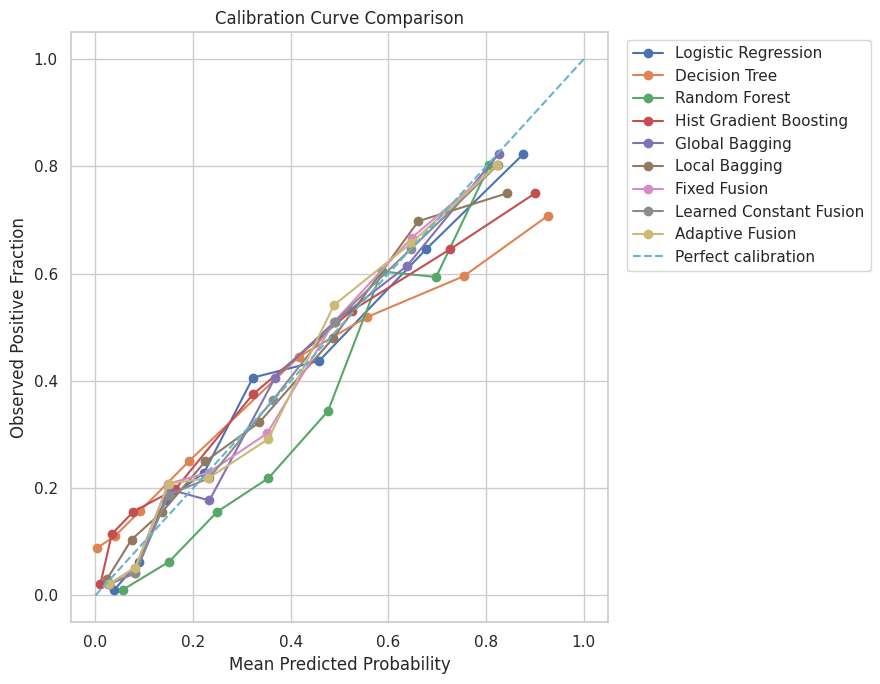

In [39]:
plt.figure(figsize=(9, 7))

for name in model_names:

    fraction_positive, mean_predicted = (
        calibration_curve(
            y,
            oof_predictions[name],
            n_bins=8,
            strategy="quantile"
        )
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Positive Fraction")

plt.title("Calibration Curve Comparison")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "results/figures/calibration_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Colab cell 28 — Paired bootstrap ROC-AUC comparison

Instead of comparing unrelated confidence intervals, we will directly examine the difference between two models on the same participants.

In [40]:
def paired_auc_bootstrap(
    y_true,
    p1,
    p2,
    n_bootstrap=3000,
    seed=42
):

    y_true = np.asarray(y_true)
    p1 = np.asarray(p1)
    p2 = np.asarray(p2)

    rng = np.random.default_rng(seed)

    differences = []

    for _ in range(n_bootstrap):

        indices = rng.integers(
            0,
            len(y_true),
            len(y_true)
        )

        ys = y_true[indices]

        if len(np.unique(ys)) < 2:
            continue

        auc1 = roc_auc_score(
            ys,
            p1[indices]
        )

        auc2 = roc_auc_score(
            ys,
            p2[indices]
        )

        differences.append(auc1 - auc2)

    return {
        "Difference": (
            roc_auc_score(y_true, p1)
            - roc_auc_score(y_true, p2)
        ),
        "CI_Lower": np.quantile(
            differences, 0.025
        ),
        "CI_Upper": np.quantile(
            differences, 0.975
        )
    }

In [41]:
comparisons = [
    ("Adaptive Fusion", "Global Bagging"),
    ("Adaptive Fusion", "Local Bagging"),
    ("Adaptive Fusion", "Fixed Fusion"),
    ("Adaptive Fusion", "Random Forest"),
    ("Adaptive Fusion", "Learned Constant Fusion")
]

comparison_results = []

for first, second in comparisons:

    result = paired_auc_bootstrap(
        y,
        oof_predictions[first],
        oof_predictions[second]
    )

    result["Model_1"] = first
    result["Model_2"] = second

    comparison_results.append(result)

comparison_df = pd.DataFrame(
    comparison_results
)

display(comparison_df)

comparison_df.to_csv(
    "results/tables/paired_auc_bootstrap.csv",
    index=False
)

,Difference,CI_Lower,CI_Upper,Model_1,Model_2
0,-0.002276,-0.008237,0.003705,Adaptive Fusion,Global Bagging
1,0.013284,0.006026,0.021143,Adaptive Fusion,Local Bagging
2,0.000985,-0.000085,0.002109,Adaptive Fusion,Fixed Fusion
3,-0.004090,-0.013852,0.006327,Adaptive Fusion,Random Forest
4,-0.002231,-0.006213,0.001729,Adaptive Fusion,Learned Constant Fusion


Interpretation: if the confidence interval for the difference excludes zero, the observed difference is inconsistent with zero under this bootstrap procedure. This is not a substitute for a complete repeated-model-training uncertainty analysis.

Colab cell 29 — Decision Curve Analysis
This examines whether using model predictions provides net benefit at different decision thresholds.

,Threshold,Treat_All,Treat_None,Global Bagging,Local Bagging,Adaptive Fusion
0,0.05,0.314693,0,0.318462,0.315241,0.318462
1,0.07,0.299955,0,0.309798,0.306578,0.306802
2,0.09,0.284570,0,0.296589,0.293455,0.298020
3,0.11,0.268493,0,0.288521,0.281177,0.287863
4,0.13,0.251676,0,0.283166,0.272285,0.277957


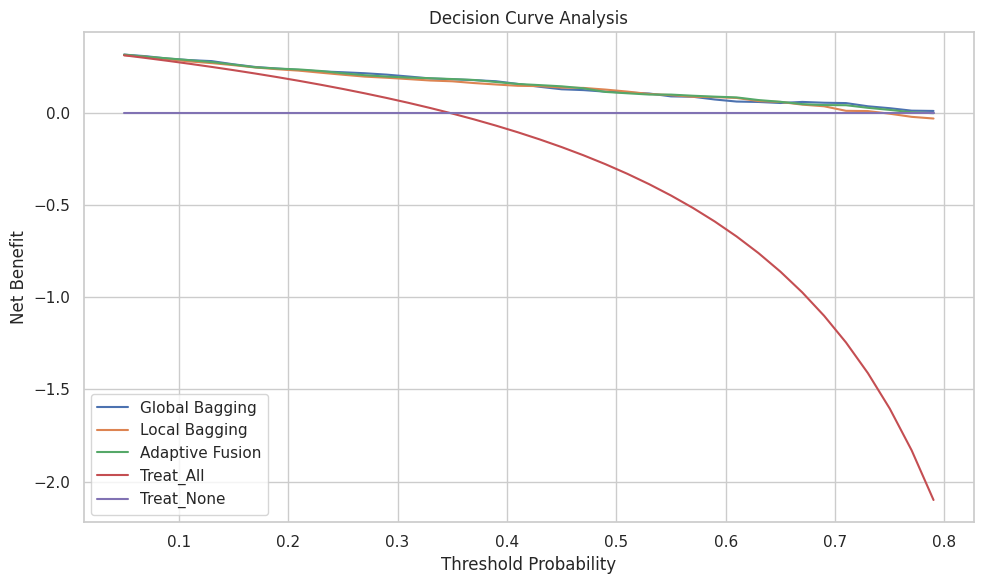

In [42]:
def net_benefit(
    y_true,
    probabilities,
    threshold
):

    predictions = (
        probabilities >= threshold
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    n = len(y_true)

    return (
        tp / n
        - (fp / n) *
        (threshold / (1 - threshold))
    )


thresholds = np.arange(
    0.05,
    0.81,
    0.02
)

dca_results = []

prevalence = np.mean(y)

for threshold in thresholds:

    row = {
        "Threshold": threshold,
        "Treat_All": (
            prevalence
            - (1 - prevalence) *
            threshold / (1 - threshold)
        ),
        "Treat_None": 0
    }

    for name in [
        "Global Bagging",
        "Local Bagging",
        "Adaptive Fusion"
    ]:

        row[name] = net_benefit(
            y,
            oof_predictions[name],
            threshold
        )

    dca_results.append(row)

dca_df = pd.DataFrame(dca_results)

display(dca_df.head())

plt.figure(figsize=(10, 6))

for name in [
    "Global Bagging",
    "Local Bagging",
    "Adaptive Fusion",
    "Treat_All",
    "Treat_None"
]:

    plt.plot(
        dca_df["Threshold"],
        dca_df[name],
        label=name
    )

plt.xlabel("Threshold Probability")
plt.ylabel("Net Benefit")

plt.title("Decision Curve Analysis")

plt.legend()

plt.tight_layout()

plt.savefig(
    "results/figures/decision_curve.png",
    dpi=300
)

plt.show()

dca_df.to_csv(
    "results/tables/decision_curve.csv",
    index=False
)

# Part 6 — Additional research experiments
Colab cell 30 — McNemar paired classification test
This tests whether two models make significantly different classification errors on the same participants.

In [43]:
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_comparison(
    y_true,
    p1,
    p2,
    threshold=0.5
):

    y_true = np.asarray(y_true)

    pred1 = (
        np.asarray(p1) >= threshold
    ).astype(int)

    pred2 = (
        np.asarray(p2) >= threshold
    ).astype(int)

    correct1 = pred1 == y_true
    correct2 = pred2 == y_true

    b = np.sum(correct1 & ~correct2)
    c = np.sum(~correct1 & correct2)

    table = [
        [0, b],
        [c, 0]
    ]

    result = mcnemar(
        table,
        exact=True
    )

    return {
        "Model_1_only_correct": b,
        "Model_2_only_correct": c,
        "P_Value": result.pvalue
    }


mcnemar_results = []

for first, second in comparisons:

    result = mcnemar_comparison(
        y,
        oof_predictions[first],
        oof_predictions[second]
    )

    result["Model_1"] = first
    result["Model_2"] = second

    mcnemar_results.append(result)

mcnemar_df = pd.DataFrame(
    mcnemar_results
)

display(mcnemar_df)

mcnemar_df.to_csv(
    "results/tables/mcnemar_results.csv",
    index=False
)

,Model_1_only_correct,Model_2_only_correct,P_Value,Model_1,Model_2
0,17,18,1.000000,Adaptive Fusion,Global Bagging
1,12,22,0.121449,Adaptive Fusion,Local Bagging
2,3,1,0.625000,Adaptive Fusion,Fixed Fusion
3,54,58,0.776965,Adaptive Fusion,Random Forest
4,11,12,1.000000,Adaptive Fusion,Learned Constant Fusion


Colab cell 31 — Ablation study
We need to demonstrate the contribution of the adaptive gate.

In [44]:
ablation_models = {

    "Global Only":
        oof_predictions["Global Bagging"],

    "Local Only":
        oof_predictions["Local Bagging"],

    "Fixed 50:50":
        oof_predictions["Fixed Fusion"],

    "Learned Constant":
        oof_predictions["Learned Constant Fusion"],

    "Age Adaptive":
        oof_predictions["Adaptive Fusion"]

}

ablation_results = []

for name, probabilities in ablation_models.items():

    metrics = calculate_metrics(
        y,
        probabilities
    )

    metrics["Experiment"] = name

    ablation_results.append(metrics)

ablation_df = pd.DataFrame(
    ablation_results
)

display(ablation_df)

ablation_df.to_csv(
    "results/tables/ablation_results.csv",
    index=False
)

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Experiment
0,0.763021,0.685345,0.593284,0.854,0.636000,0.834530,0.695153,0.156374,0.474017,Global Only
1,0.774740,0.703863,0.611940,0.862,0.654691,0.818970,0.669121,0.163261,0.497558,Local Only
2,0.759115,0.681223,0.582090,0.854,0.627767,0.831269,0.688607,0.157304,0.478494,Fixed 50:50
3,0.763021,0.683761,0.597015,0.852,0.637450,0.834485,0.695617,0.156412,0.474542,Learned Constant
4,0.761719,0.685590,0.585821,0.856,0.631791,0.832254,0.691089,0.156972,0.477425,Age Adaptive


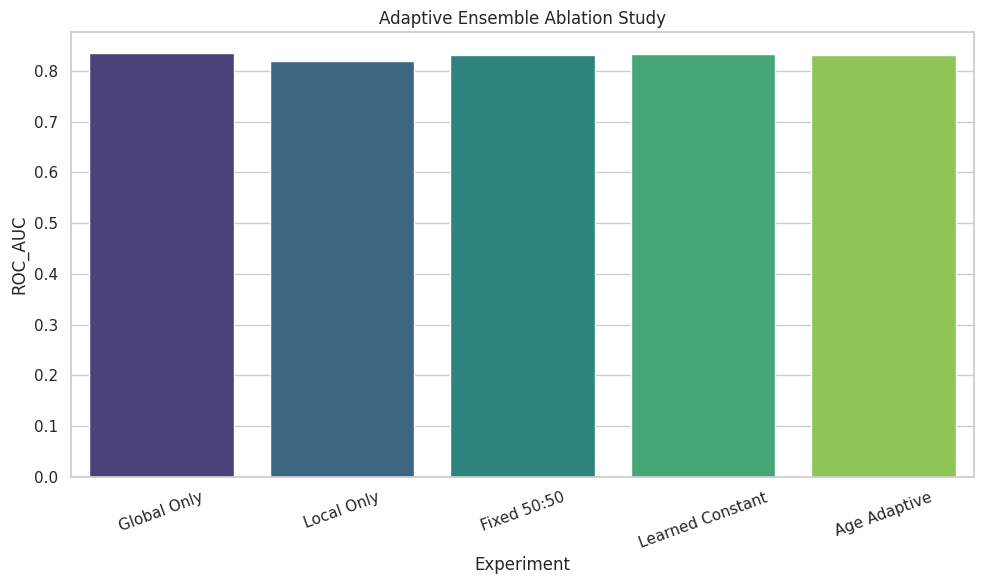

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=ablation_df,
    x="Experiment",
    y="ROC_AUC",
    hue="Experiment",
    palette="viridis",
    legend=False
)

plt.title("Adaptive Ensemble Ablation Study")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "results/figures/ablation_comparison.png",
    dpi=300
)

plt.show()

Colab cell 32 — Age-related prevalence statistical test
We will investigate whether diabetes prevalence differs across our age groups

In [46]:
from scipy.stats import chi2_contingency

age_contingency = pd.crosstab(
    data_clean["Age_Group"],
    data_clean["Outcome"]
)

chi2, p_value, dof, expected = (
    chi2_contingency(age_contingency)
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

print("\nExpected frequencies:")
display(
    pd.DataFrame(
        expected,
        index=age_contingency.index,
        columns=age_contingency.columns
    )
)

Chi-square statistic: 73.80892085951109
P-value: 6.521685313585261e-16
Degrees of freedom: 3

Expected frequencies:


Outcome,0,1
Age_Group,,
21-30,271.484375,145.515625
31-40,102.213542,54.786458
41-50,73.567708,39.432292
51+,52.734375,28.265625


Colab cell 33 — Permutation feature importance

,Feature,Importance_Mean,Importance_Std
1,Glucose,0.138868,0.012034
5,BMI,0.070695,0.006969
7,Age,0.048606,0.005500
6,DiabetesPedigreeFunction,0.027607,0.002411
4,Insulin,0.026316,0.004259
0,Pregnancies,0.015212,0.001911
3,SkinThickness,0.014360,0.001923
2,BloodPressure,0.011937,0.000960


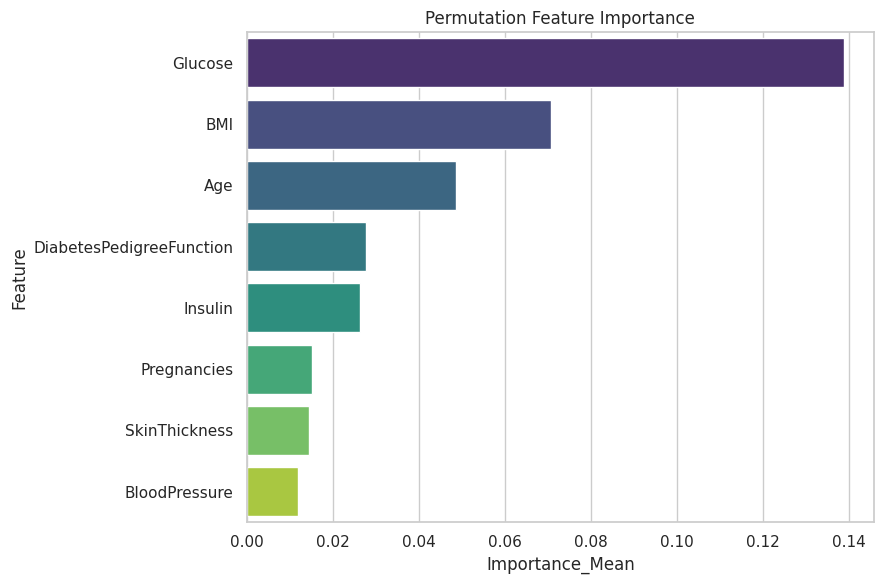

In [47]:
final_rf = clone(
    baseline_models["Random Forest"]
)

final_rf.fit(X, y)

importance = permutation_importance(
    final_rf,
    X,
    y,
    scoring="roc_auc",
    n_repeats=30,
    random_state=SEED,
    n_jobs=-1
)

importance_df = pd.DataFrame({

    "Feature": FEATURES,

    "Importance_Mean": (
        importance.importances_mean
    ),

    "Importance_Std": (
        importance.importances_std
    )

}).sort_values(
    "Importance_Mean",
    ascending=False
)

display(importance_df)

importance_df.to_csv(
    "results/tables/feature_importance.csv",
    index=False
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x="Importance_Mean",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Permutation Feature Importance")

plt.tight_layout()

plt.savefig(
    "results/figures/feature_importance.png",
    dpi=300
)

plt.show()

Part 7 — External validation and final model
Colab cell 34 — Train final development model
After internal evaluation, we will fit the final development model using all PIMA observations.

The external dataset must not be used during this training process.

In [48]:
# Tune global model using development data
final_global = tune_global_model(
    X,
    y
)

# Generate OOF predictions for gate training
final_oof_global, final_oof_local = (
    generate_oof_predictions_tuned(
        X,
        y,
        final_global,
        n_splits=5
    )
)

# Train final gate
final_gate = fit_adaptive_gate(
    y,
    final_oof_global,
    final_oof_local,
    X["Age"].values
)

# Fit global model on all development data
final_global.fit(X, y)

# Fit local models on all development data
final_local_models = train_local_models(
    X,
    y
)

print("Final global model trained.")

print(
    "Final local models:",
    list(final_local_models.keys())
)

print("Final gate:", final_gate)

Best parameters: {'model__n_estimators': 150, 'model__max_samples': 0.8, 'model__estimator__min_samples_leaf': 8, 'model__estimator__max_depth': 5}
Best inner CV ROC-AUC: 0.8378040273408329
Tuned OOF fold 1/5 completed
Tuned OOF fold 2/5 completed
Tuned OOF fold 3/5 completed
Tuned OOF fold 4/5 completed
Tuned OOF fold 5/5 completed
Final global model trained.
Final local models: ['21-30', '31-40', '41-50', '51+']
Final gate: {'w0': np.float64(0.13012217511827587), 'w1': np.float64(-0.07903973753662859), 'age_mean': np.float64(33.240885416666664), 'age_std': np.float64(11.752572655994182), 'success': True}


Colab cell 35 — Save the models

In [49]:
import joblib

joblib.dump(
    final_global,
    "results/models/global_bagging.pkl"
)

joblib.dump(
    final_local_models,
    "results/models/local_models.pkl"
)

joblib.dump(
    final_gate,
    "results/models/adaptive_gate.pkl"
)

joblib.dump(
    final_rf,
    "results/models/random_forest.pkl"
)

print("Models saved successfully.")

Models saved successfully.


# Colab cell 36 — External dataset upload
This is a general external-validation interface.

The uploaded dataset must have the same predictor definitions, measurement units, eligibility criteria and target meaning as the development data.

Expected columns:
Pregnancies
Glucose
BloodPressure
SkinThickness
Insulin
BMI
DiabetesPedigreeFunction
Age
Outcome


For NHANES, you must first create a scientifically justified harmonized dataset. The following cell does not automatically convert raw NHANES data into PIMA-equivalent data.

In [51]:
from google.colab import files

uploaded = files.upload()

external_filename = list(uploaded.keys())[0]

external_data = pd.read_csv(
    external_filename
)

print("External dataset shape:")
print(external_data.shape)

display(external_data.head())

Saving diabetes.csv to diabetes.csv
External dataset shape:
(2000, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,2,138,62,35,0,33.6,0.127,47,1
1,0,84,82,31,125,38.2,0.233,23,0
2,0,145,0,0,0,44.2,0.630,31,1
3,0,135,68,42,250,42.3,0.365,24,1
4,1,139,62,41,480,40.7,0.536,21,0


Colab cell 37 — External dataset preparation

In [52]:
external_data.columns = [
    str(col).strip()
    for col in external_data.columns
]

required_external = FEATURES + ["Outcome"]

missing = [
    col for col in required_external
    if col not in external_data.columns
]

if missing:

    raise ValueError(
        f"Missing external dataset columns: {missing}"
    )

external_data = external_data[
    required_external
].copy()

external_data["Outcome"] = pd.to_numeric(
    external_data["Outcome"],
    errors="coerce"
)

external_data = external_data.dropna(
    subset=["Outcome"]
)

external_data["Outcome"] = (
    external_data["Outcome"].astype(int)
)

if not set(external_data["Outcome"].unique()).issubset({0, 1}):
    raise ValueError("Outcome must contain only 0 and 1.")

for col in zero_columns:

    external_data.loc[
        external_data[col] == 0,
        col
    ] = np.nan

X_external = external_data[FEATURES].copy()
y_external = external_data["Outcome"].copy()

print("External dataset prepared:")
print(X_external.shape)

display(
    y_external.value_counts()
)

External dataset prepared:
(2000, 8)


,count
Outcome,
0,1316
1,684


Colab cell 38 — External validation prediction

In [53]:
p_external_global = (
    final_global.predict_proba(
        X_external
    )[:, 1]
)

p_external_local = predict_local_models(
    X_external,
    final_global,
    final_local_models
)

p_external_adaptive, external_alpha = (
    apply_adaptive_gate(
        final_gate,
        p_external_global,
        p_external_local,
        X_external["Age"].values
    )
)

external_predictions = {

    "Global Bagging": p_external_global,

    "Local Bagging": p_external_local,

    "Fixed Fusion": (
        0.5 * p_external_global
        + 0.5 * p_external_local
    ),

    "Adaptive Fusion": p_external_adaptive

}

external_results = []

for name, probabilities in external_predictions.items():

    metrics = calculate_metrics(
        y_external,
        probabilities
    )

    metrics["Model"] = name

    external_results.append(metrics)

external_results_df = pd.DataFrame(
    external_results
)

display(external_results_df)

external_results_df.to_csv(
    "results/tables/external_validation.csv",
    index=False
)

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Model
0,0.8295,0.780687,0.697368,0.898176,0.736680,0.910521,0.828336,0.119005,0.374022,Global Bagging
1,0.8575,0.825449,0.739766,0.918693,0.780262,0.934577,0.879682,0.104840,0.342271,Local Bagging
2,0.8550,0.818770,0.739766,0.914894,0.777266,0.927113,0.862231,0.110108,0.355136,Fixed Fusion
3,0.8510,0.808307,0.739766,0.908815,0.772519,0.926721,0.860882,0.110389,0.355770,Adaptive Fusion


Colab cell 39 — External age subgroup performance

In [54]:
external_data["Age_Group"] = pd.cut(
    external_data["Age"],
    bins=AGE_BINS,
    labels=AGE_LABELS,
    right=True,
    include_lowest=True
)

external_subgroup_results = []

for group in AGE_LABELS:

    mask = (
        external_data["Age_Group"].astype(str).values
        == group
    )

    if mask.sum() == 0:
        continue

    y_group = y_external.iloc[
        np.where(mask)[0]
    ]

    for name, probabilities in external_predictions.items():

        p_group = probabilities[mask]

        metrics = calculate_metrics(
            y_group,
            p_group
        )

        metrics["Age_Group"] = group
        metrics["Model"] = name
        metrics["Sample_Size"] = len(y_group)

        external_subgroup_results.append(metrics)

external_subgroup_df = pd.DataFrame(
    external_subgroup_results
)

display(external_subgroup_df)

external_subgroup_df.to_csv(
    "results/tables/external_subgroup_results.csv",
    index=False
)

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Age_Group,Model,Sample_Size
0,0.867089,0.791946,0.504274,0.964450,0.616188,0.922494,0.761872,0.091697,0.298338,21-30,Global Bagging,1106
1,0.867993,0.833333,0.470085,0.974771,0.601093,0.939191,0.813559,0.085557,0.282085,21-30,Local Bagging,1106
2,0.874322,0.851852,0.491453,0.977064,0.623306,0.932232,0.793950,0.087925,0.288889,21-30,Fixed Fusion,1106
3,0.868897,0.815603,0.491453,0.970183,0.613333,0.931364,0.788654,0.088209,0.289639,21-30,Adaptive Fusion,1106
4,0.789082,0.768473,0.804124,0.775120,0.785894,0.882208,0.853380,0.143551,0.444983,31-40,Global Bagging,403
5,0.848635,0.824390,0.871134,0.827751,0.847118,0.923840,0.899823,0.129311,0.420185,31-40,Local Bagging,403
6,0.843672,0.810427,0.881443,0.808612,0.844444,0.909609,0.878416,0.134575,0.429415,31-40,Fixed Fusion,403
7,0.838710,0.802817,0.881443,0.799043,0.840295,0.908696,0.877901,0.134976,0.430085,31-40,Adaptive Fusion,403
8,0.750000,0.790419,0.771930,0.720000,0.781065,0.828912,0.860474,0.167903,0.504055,41-50,Global Bagging,296
9,0.834459,0.821053,0.912281,0.728000,0.864266,0.921357,0.945130,0.129060,0.418207,41-50,Local Bagging,296


# Part 8 — Final results and reproducibility package
Colab cell 40 — Final summary dashboard

In [55]:
print("\n" + "=" * 70)
print("AGE-AWARE DIABETES RESEARCH: FINAL SUMMARY")
print("=" * 70)

print("\nDATASET")
print("Total participants:", len(data_clean))
print("Features:", len(FEATURES))
print("Diabetic:", int(y.sum()))
print("Non-diabetic:", int((y == 0).sum()))

print("\nAGE DISTRIBUTION")
display(age_summary)

print("\nOVERALL PERFORMANCE")
display(results_df)

print("\nAGE SUBGROUP PERFORMANCE")
display(subgroup_df)

print("\nAGE PERFORMANCE GAPS")
display(gap_df)

print("\nADAPTIVE GATE")
print(final_gate)

print("\nABLATION STUDY")
display(ablation_df)

print("\nEXTERNAL VALIDATION")
if os.path.exists(
    "results/tables/external_validation.csv"
):
    display(external_results_df)

print("\nResearch experiment completed.")


AGE-AWARE DIABETES RESEARCH: FINAL SUMMARY

DATASET
Total participants: 768
Features: 8
Diabetic: 268
Non-diabetic: 500

AGE DISTRIBUTION


,Total,Diabetic,Mean_Age,Non_Diabetic,Diabetes_Prevalence
Age_Group,,,,,
21-30,417,90,24.599520,327,21.582734
31-40,157,76,35.146497,81,48.407643
41-50,113,64,44.327434,49,56.637168
51+,81,38,58.567901,43,46.913580



OVERALL PERFORMANCE


,Model,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
2,Random Forest,0.766927,0.638629,0.764925,0.768,0.696095,0.836343,0.695746,0.162231,0.491395
4,Global Bagging,0.763021,0.685345,0.593284,0.854,0.636000,0.834530,0.695153,0.156374,0.474017
7,Learned Constant Fusion,0.763021,0.683761,0.597015,0.852,0.637450,0.834485,0.695617,0.156412,0.474542
0,Logistic Regression,0.768229,0.708333,0.570896,0.874,0.632231,0.834007,0.708767,0.157097,0.479005
8,Adaptive Fusion,0.761719,0.685590,0.585821,0.856,0.631791,0.832254,0.691089,0.156972,0.477425
6,Fixed Fusion,0.759115,0.681223,0.582090,0.854,0.627767,0.831269,0.688607,0.157304,0.478494
5,Local Bagging,0.774740,0.703863,0.611940,0.862,0.654691,0.818970,0.669121,0.163261,0.497558
3,Hist Gradient Boosting,0.757812,0.664000,0.619403,0.832,0.640927,0.814985,0.663185,0.169962,0.525893
1,Decision Tree,0.727865,0.601375,0.652985,0.768,0.626118,0.773470,0.602610,0.188597,0.751947



AGE SUBGROUP PERFORMANCE


,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Age_Group,Model,Sample_Size,Positive_Cases
0,0.836930,0.683333,0.455556,0.941896,0.546667,0.853551,0.651373,0.117856,0.373392,21-30,Logistic Regression,417,90
1,0.791367,0.517241,0.500000,0.871560,0.508475,0.750119,0.503002,0.153202,0.616519,21-30,Decision Tree,417,90
2,0.798561,0.531250,0.566667,0.862385,0.548387,0.836323,0.607937,0.132036,0.414165,21-30,Random Forest,417,90
3,0.815348,0.597015,0.444444,0.917431,0.509554,0.796398,0.539014,0.137045,0.443293,21-30,Hist Gradient Boosting,417,90
4,0.822542,0.642857,0.400000,0.938838,0.493151,0.832790,0.621351,0.122466,0.384537,21-30,Global Bagging,417,90
5,0.832134,0.727273,0.355556,0.963303,0.477612,0.815664,0.598832,0.127962,0.402483,21-30,Local Bagging,417,90
6,0.820144,0.647059,0.366667,0.944954,0.468085,0.826809,0.608475,0.124135,0.389738,21-30,Fixed Fusion,417,90
7,0.822542,0.642857,0.400000,0.938838,0.493151,0.830717,0.620655,0.123284,0.386732,21-30,Learned Constant Fusion,417,90
8,0.820144,0.647059,0.366667,0.944954,0.468085,0.827455,0.609033,0.124003,0.389250,21-30,Adaptive Fusion,417,90
9,0.700637,0.745763,0.578947,0.814815,0.651852,0.779890,0.735369,0.195165,0.587864,31-40,Logistic Regression,157,76


... (3 outputs left out)

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Experiment
0,0.763021,0.685345,0.593284,0.854,0.636000,0.834530,0.695153,0.156374,0.474017,Global Only
1,0.774740,0.703863,0.611940,0.862,0.654691,0.818970,0.669121,0.163261,0.497558,Local Only
2,0.759115,0.681223,0.582090,0.854,0.627767,0.831269,0.688607,0.157304,0.478494,Fixed 50:50
3,0.763021,0.683761,0.597015,0.852,0.637450,0.834485,0.695617,0.156412,0.474542,Learned Constant
4,0.761719,0.685590,0.585821,0.856,0.631791,0.832254,0.691089,0.156972,0.477425,Age Adaptive



EXTERNAL VALIDATION


,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Model
0,0.8295,0.780687,0.697368,0.898176,0.736680,0.910521,0.828336,0.119005,0.374022,Global Bagging
1,0.8575,0.825449,0.739766,0.918693,0.780262,0.934577,0.879682,0.104840,0.342271,Local Bagging
2,0.8550,0.818770,0.739766,0.914894,0.777266,0.927113,0.862231,0.110108,0.355136,Fixed Fusion
3,0.8510,0.808307,0.739766,0.908815,0.772519,0.926721,0.860882,0.110389,0.355770,Adaptive Fusion



Research experiment completed.


Colab cell 41 — Export all results

In [56]:
import shutil

shutil.make_archive(
    "Age_Aware_Diabetes_Research_Results",
    "zip",
    "results"
)

print("Results archive created.")

from google.colab import files

files.download(
    "Age_Aware_Diabetes_Research_Results.zip"
)

Results archive created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Colab cell 42 — Export the dataset audit

In [57]:
data_clean.to_csv(
    "results/tables/cleaned_pima_dataset.csv",
    index=False
)

predictions_export = pd.DataFrame({
    "Actual": y.values,
    "Age": X["Age"].values,
    "Age_Group": get_age_group(
        X["Age"]
    ).astype(str).values,
    "Global_Bagging": oof_predictions[
        "Global Bagging"
    ],
    "Local_Bagging": oof_predictions[
        "Local Bagging"
    ],
    "Adaptive_Fusion": oof_predictions[
        "Adaptive Fusion"
    ],
    "Global_Weight": oof_alpha
})

predictions_export.to_csv(
    "results/tables/oof_predictions.csv",
    index=False
)

print("Out-of-fold predictions exported.")

Out-of-fold predictions exported.


# Colab cell 43 — SHAP explainability (optional)
We installed SHAP in the first cell. This provides a model-level explanation for the Random Forest benchmark.

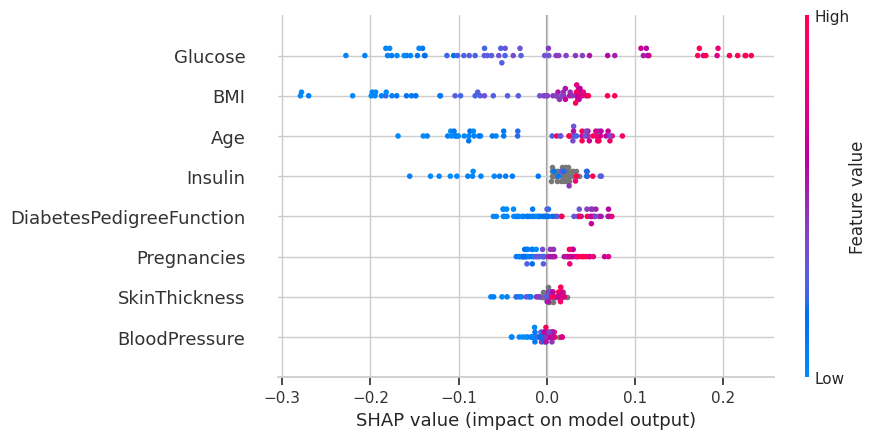

<Figure size 640x480 with 0 Axes>

In [58]:
import shap

def rf_predict_function(values):

    frame = pd.DataFrame(
        values,
        columns=FEATURES
    )

    return final_rf.predict_proba(
        frame
    )[:, 1]


background = X.sample(
    min(40, len(X)),
    random_state=SEED
)

explain_samples = X.sample(
    min(60, len(X)),
    random_state=SEED + 1
)

explainer = shap.Explainer(
    rf_predict_function,
    background,
    algorithm="permutation"
)

shap_values = explainer(
    explain_samples,
    max_evals=2 * len(FEATURES) + 1
)

shap.plots.beeswarm(
    shap_values,
    show=True
)

plt.savefig(
    "results/figures/shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)